In [2]:
import textwrap
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Legend text labels wrapped to roughly half the original visual width
labels = [
    "perfect calibration",
    textwrap.fill(
        "LOESS on pseudo-observations, median of the out-of-bag replicates (2.5-97.5 band)",
        width=40,
    ),
    textwrap.fill(
        "risk quartiles of the pooled out-of-bag risk, 1 - KM (95% CI)",
        width=40,
    ),
]

# Replicate the styling of the legend handles
handles = [
    Line2D(
        [0],
        [0],
        color="#627882",
        linestyle=(0, (4, 3)),
        linewidth=1.8,
    ),
    Line2D(
        [0],
        [0],
        color="#0072B2",
        linestyle="-",
        linewidth=2.5,
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="white",
        markeredgecolor="#D55E00",
        markeredgewidth=2.0,
        markersize=6,
    ),
]

# Render only the legend
fig = plt.figure(figsize=(3.5, 2))
legend = fig.legend(
    handles=handles,
    labels=labels,
    loc="center",
    frameon=False,
    fontsize=9.5,
    handlelength=2.2,
    handletextpad=0.8,
    labelspacing=0.8,
)

# Export tightly cropped to PDF
fig.savefig(
    "legend_half_width.pdf",
    format="pdf",
    bbox_inches=legend.get_window_extent().transformed(
        fig.dpi_scale_trans.inverted()
    ),
    pad_inches=0.02,
)
plt.close(fig)

# Calibration of the deployed 5-year model

Discrimination (C-index, SurvSHAP) says how well the model *orders* patients. This
notebook asks the other question: when the model says 4%, do 4% of those patients
recur? It is the calibration evidence for the thesis, for the **deployed** model and
no other - the L1-Coxnet in `deployed_model/coxnet_model_bundle.pkl`, at its fitted
hyperparameters, on the full 3228-patient cohort administratively censored at 5 years.

Three facts shape every choice below.

1. **27 events.** That is the entire outcome signal. Decile calibration plots, per-bin
   event proportions and anything else that needs events *inside* a bin are not
   available; the notebook uses four risk groups and reports how few events each holds.
2. **Censoring.** Almost every patient is censored before 5 years, so the observed side
   of every comparison is a Kaplan-Meier estimate, never a raw event proportion. The
   smooth curve uses jackknife **pseudo-observations**, which carry the censoring
   correction into a per-patient quantity a smoother can consume.
3. **Optimism.** The Breslow baseline is fitted on the same patients it is scored on,
   so the apparent fit *cannot* be miscalibrated in the large - its mean predicted risk
   is pinned to the cohort Kaplan-Meier by construction. Every headline number is
   therefore reported three ways - **apparent**, **out-of-bag** and
   **optimism-corrected** - from one event-stratified bootstrap in which the scaler and
   the model are refitted on the in-bag rows of every replicate. That is how this repo
   assesses metrics: repeated stratified cross-validation appears in the grid searches
   because it is cheap enough to run over a hyperparameter grid, but nothing is
   *reported* from it. `cox.ipynb` reports
   `subsampling_bootstrap_optimism_grid_search` at `n_bootstraps=500`, and
   `threshold_2.0_copy.ipynb` validates the threshold rule with an in-bag/out-of-bag
   replicate loop; section 5 is the same machinery pointed at calibration.

Run order is top to bottom. Every tunable quantity lives in `CONFIG` in the next cell;
nothing below it hardcodes a value that appears in it. Runtime is dominated by the
validation bootstrap in section 5 - a few minutes at `n_bootstrap = 500` on eight cores.

In [1]:
# =============================================================================
# CONFIG - the single source of truth for this notebook.
# =============================================================================
CONFIG = {
    # ---- provenance ---------------------------------------------------------
    "repo_root": "../../../",
    "data_csv": "../../data/data_cox/data.csv",
    "diagnosis_txt": "../../data/data_cox/diagnosis.txt",
    "treatment_txt": "../../data/data_cox/treatment.txt",
    "bundle_metadata": "deployed_model/bundle_metadata.json",
    "output_dir": "calibration",

    # ---- cohort (identical to threshold_2.0_copy.ipynb / threshold_app.ipynb)
    "id_col": "PERSON_ID",
    "event_col": "Regional LN recurrence",
    "time_col": "Survival days",
    "administrative_cap_days": 1826.0,
    "continuous_features": [
        "Age", "Ki67 positive cells (%) at CB", "Conventional RT fraction",
        "Total administered dose", "Boost dose administered",
    ],

    # ---- the fixed model ----------------------------------------------------
    # Never re-tuned here. Refitted inside every replicate, reselected nowhere.
    "model_params": {"alphas": [0.000853168], "l1_ratio": 1.0, "fit_baseline_model": True},
    "expected_apparent_c_index": 0.9200067108464055,   # bundle_metadata.json

    # ---- internal validation: the repo's event-stratified bootstrap ---------
    # Metrics in this repo are assessed by bootstrap, not by the cross-validation
    # that ranked the hyperparameters: cox.ipynb reports
    # functions.repeated_cv.subsampling_bootstrap_optimism_grid_search at
    # n_bootstraps=500 / base_random_state=42, and threshold_2.0_copy.ipynb
    # validates the deployed threshold rule with an in-bag/out-of-bag replicate
    # loop. Same scheme here: one fit per replicate, read three ways.
    "n_bootstrap": 500,
    "bootstrap_seed": 202608,
    "stratify_on_event": True,      # keeps all 27 events in every replicate
    "min_oob_events": 3,            # below this a replicate says nothing; counted as failed
    "ipa_min_oob_events": 3,        # IPA is 0/0 until the held-out patients have events
    "compute_optimism": True,       # False drops the corrected column and a third of the runtime
    "progress_every": 25,

    # ---- evaluation grid ----------------------------------------------------
    "horizons": [365.0, 730.0, 1095.0, 1460.0, 1825.0],
    "plot_horizons": [365.0, 1095.0, 1825.0],
    "primary_horizon": 1825.0,
    "time_grid_step_days": 15.0,
    "time_display_divisor": 365.25,
    "time_display_unit": "years",

    # ---- calibration estimators ---------------------------------------------
    # n_risk_groups = 4: at five, one group already holds zero events.
    "n_risk_groups": 4,
    "loess_frac": 0.5,
    "loess_space": "cloglog",           # 'cloglog' or 'risk'; see the smoothing cell
    "ci_alpha": 0.05,
    "curve_grid_points": 400,           # x-grid the replicate curves are read on
    "plot_risk_upper_quantile": 0.99,   # x-axis truncation for the calibration panels

    # ---- deployed zones (bundle_metadata.json; reproduced and asserted below)
    "zone_labels": ["zone_1_low", "zone_2_mid_low", "zone_3_mid_high", "zone_4_high"],
    "zone_display_names": ["Low", "Mid-low", "Mid-high", "High"],
    "zone_expected_sizes": [1227, 1234, 276, 491],

    # ---- presentation (matches threshold_validation/) ------------------------
    "figure_width_in": 7.0,
    "font_size": 9,
    "palette_calibration": ["#0072B2", "#D55E00"],   # smooth curve, risk groups
    # apparent, out-of-bag, optimism-corrected
    "palette_validation": ["#8C8C8C", "#0072B2", "#333333"],
    "palette_zones": ["#0072B2", "#56B4E9", "#E69F00", "#D55E00"],
    "save_figures": True,
    "save_tables": True,
    "n_jobs": -1,
    "random_seed": 42,
}

In [2]:
# ---- Imports, export defaults and library versions --------------------------
import os
import sys
import json
import pickle
import time
import platform
import traceback
import warnings
from datetime import datetime

REPO_ROOT = os.path.abspath(CONFIG["repo_root"])
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import scipy
import scipy.stats
import sklearn
import sksurv
import joblib
import lifelines
import statsmodels
from joblib import Parallel, delayed
from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import MinMaxScaler
from sksurv.util import Surv
from sksurv.linear_model import CoxnetSurvivalAnalysis
from sksurv.metrics import brier_score, concordance_index_censored, concordance_index_ipcw
from statsmodels.nonparametric.smoothers_lowess import lowess
from lifelines import CoxPHFitter

OUTPUT_DIR = os.path.abspath(CONFIG["output_dir"])
os.makedirs(OUTPUT_DIR, exist_ok=True)

# lifelines warns about the event count at every horizon; scikit-survival warns when
# the L1 path stops early on a resample. Both are the premise of this notebook rather
# than news, and the reported intervals already carry them - while a path that actually
# diverged is caught explicitly in run_replicate and counted as a failed replicate, not
# silenced. The bootstrap workers are separate processes and do not inherit these
# filters, so run_replicate sets them again.
QUIET_WARNINGS = (
    lifelines.exceptions.StatisticalWarning,
    lifelines.exceptions.ApproximationWarning,
    lifelines.exceptions.ConvergenceWarning,
    ConvergenceWarning,                       # sklearn's, raised by CoxnetSurvivalAnalysis
)
for _cat in QUIET_WARNINGS:
    warnings.filterwarnings("ignore", category=_cat)

LIB_VERSIONS = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "scikit-survival": sksurv.__version__,
    "lifelines": lifelines.__version__,
    "statsmodels": statsmodels.__version__,
    "joblib": joblib.__version__,
    "matplotlib": matplotlib.__version__,
}
print("run started :", datetime.now().isoformat(timespec="seconds"))
print("output dir  :", OUTPUT_DIR)
print("library versions:")
for _k, _v in LIB_VERSIONS.items():
    print(f"  {_k:<16s} {_v}")

# Thesis export defaults: vector PDF, no in-figure titles, >= 8 pt type.
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "font.size": CONFIG["font_size"],
    "axes.titlesize": CONFIG["font_size"],
    "axes.labelsize": CONFIG["font_size"],
    "xtick.labelsize": CONFIG["font_size"] - 1,
    "ytick.labelsize": CONFIG["font_size"] - 1,
    "legend.fontsize": CONFIG["font_size"] - 1,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 1.6,
})

Z = float(scipy.stats.norm.ppf(1.0 - CONFIG["ci_alpha"] / 2.0))
DIV = float(CONFIG["time_display_divisor"])
HORIZONS = np.asarray(CONFIG["horizons"], dtype=float)
PRIMARY = float(CONFIG["primary_horizon"])
PLOT_HORIZONS = np.asarray(CONFIG["plot_horizons"], dtype=float)
PLOT_SET = {float(h) for h in PLOT_HORIZONS}
PLO, PHI = 100 * CONFIG["ci_alpha"] / 2.0, 100 * (1.0 - CONFIG["ci_alpha"] / 2.0)

WRITTEN = []


def _save(fig, stem):
    """Write a figure as PNG + PDF into OUTPUT_DIR and record the paths."""
    if not CONFIG["save_figures"]:
        return
    for ext in ("png", "pdf"):
        path = os.path.join(OUTPUT_DIR, f"{stem}.{ext}")
        fig.savefig(path)
        WRITTEN.append(os.path.relpath(path, os.getcwd()))


def _save_table(df, stem, tex_caption=None, tex_label=None, float_format="%.4f"):
    """Write a table as CSV (always) and LaTeX (when a caption is supplied)."""
    if not CONFIG["save_tables"]:
        return
    path = os.path.join(OUTPUT_DIR, f"{stem}.csv")
    df.to_csv(path, index=False)
    WRITTEN.append(os.path.relpath(path, os.getcwd()))
    if tex_caption is not None:
        tex = df.to_latex(index=False, escape=True, float_format=float_format,
                          caption=tex_caption, label=tex_label, position="htbp")
        path = os.path.join(OUTPUT_DIR, f"{stem}.tex")
        with open(path, "w", encoding="utf-8") as fh:
            fh.write(tex)
        WRITTEN.append(os.path.relpath(path, os.getcwd()))

run started : 2026-08-31T16:52:49
output dir  : c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\new_approaches\models\5y\calibration
library versions:
  python           3.11.13
  numpy            2.3.1
  pandas           2.3.2
  scipy            1.16.2
  scikit-learn     1.7.2
  scikit-survival  0.25.0
  lifelines        0.30.0
  statsmodels      0.14.5
  joblib           1.5.2
  matplotlib       3.10.6


## 1. Cohort and the fixed model

The design matrix is built exactly as in `threshold_2.0_copy.ipynb` - same file, same
administrative cap, same continuous columns - so the risks scored here are the risks the
deployed threshold table was cut from.

One deliberate difference: `data_x` is kept **unscaled**. The apparent fit min-max scales
on the full cohort, matching the bundle; every bootstrap replicate refits the scaler on
its own in-bag rows, because a scaler fitted on all 3228 patients is a channel through
which a held-out patient leaks into their own prediction.

In [3]:
# ---- data_x (unscaled), y, and the evaluation time grid ---------------------
_raw = pd.read_csv(CONFIG["data_csv"])
survival_dataset = _raw.drop(columns=[c for c in ["Unnamed: 0"] if c in _raw.columns])

with open(CONFIG["diagnosis_txt"], "r") as _f:
    diagnosis_variables = [line.strip() for line in _f if line.strip()]
with open(CONFIG["treatment_txt"], "r") as _f:
    treatment_variables = [line.strip() for line in _f if line.strip()]
feature_columns = treatment_variables + diagnosis_variables

_missing = [c for c in feature_columns if c not in survival_dataset.columns]
if _missing:
    raise KeyError(f"Feature columns absent from the data file: {_missing}")

# Administrative censoring at the cap (identical to the existing notebooks).
_cap = float(CONFIG["administrative_cap_days"])
_beyond = survival_dataset[CONFIG["time_col"]] > _cap
survival_dataset.loc[_beyond, CONFIG["event_col"]] = 0
survival_dataset.loc[_beyond, CONFIG["time_col"]] = _cap

data_x = survival_dataset[feature_columns].reset_index(drop=True)
y = Surv.from_arrays(
    event=survival_dataset[CONFIG["event_col"]],
    time=survival_dataset[CONFIG["time_col"]],
)
EVENT = y[y.dtype.names[0]].astype(bool)
TIME = y[y.dtype.names[1]].astype(float)
PATIENT_IDS = survival_dataset[CONFIG["id_col"]].to_numpy()
N_PATIENTS = int(data_x.shape[0])
COLS_TO_SCALE = [c for c in CONFIG["continuous_features"] if c in data_x.columns]

# The union of the reporting horizons and a regular grid, so the time-varying
# figures and the horizon tables are read out of one prediction pass.
_step = float(CONFIG["time_grid_step_days"])
EVAL_TIMES = np.unique(np.concatenate([
    np.arange(_step, PRIMARY + _step / 2.0, _step), HORIZONS, [PRIMARY],
]))
EVAL_TIMES = EVAL_TIMES[EVAL_TIMES <= PRIMARY]
HZ_IDX = np.array([int(np.flatnonzero(EVAL_TIMES == h)[0]) for h in HORIZONS])

print(f"rows (patients)   : {N_PATIENTS}")
print(f"events by {_cap:.0f} d  : {int(EVENT.sum())}  "
      f"({100 * EVENT.mean():.2f}% of the cohort)")
print(f"censored          : {int((~EVENT).sum())}")
print(f"follow-up (days)  : {TIME.min():.0f} - {TIME.max():.0f}")
print(f"features          : {data_x.shape[1]}  (min-max scaled: {len(COLS_TO_SCALE)})")
print(f"missing cells     : {int(data_x.isna().sum().sum())}")
print(f"evaluation grid   : {EVAL_TIMES.size} points, {EVAL_TIMES[0]:.0f}-{EVAL_TIMES[-1]:.0f} d")
print(f"events per horizon: "
      + ", ".join(f"{h / DIV:.0f}y={int((EVENT & (TIME <= h)).sum())}" for h in HORIZONS))

rows (patients)   : 3228
events by 1826 d  : 27  (0.84% of the cohort)
censored          : 3201
follow-up (days)  : 25 - 1826
features          : 30  (min-max scaled: 5)
missing cells     : 0
evaluation grid   : 125 points, 15-1825 d
events per horizon: 1y=5, 2y=10, 3y=16, 4y=22, 5y=27


## 2. The apparent fit

Scaler and model fitted on all 3228 patients, then scored on the same 3228. This is the
deployed model scoring the cohort it was built from. Reproducing the bundle's C-index to
12 decimals is the check that this notebook is looking at the deployed object and not a
near-miss of it.

Nothing here is validation. The apparent fit is the reference point: section 5 resamples
the cohort, refits this same configuration on every resample, and measures how far these
numbers sit from what the model does on patients it has not seen.

In [4]:
# ---- One fit: scale on train, fit Coxnet, return risk on the eval grid ------
def fit_and_score(x_train, y_train, x_score, times):
    """Return (linear predictor, cumulative-incidence matrix, n non-zero coefs).

    `x_train` / `x_score` are UNSCALED frames; the min-max scaler is fitted on
    `x_train` only. The risk matrix is 1 - S(t) with S from the Breslow baseline
    that `fit_baseline_model=True` attaches to the fitted Coxnet.
    """
    scaler = MinMaxScaler()
    xt, xs = x_train.copy(), x_score.copy()
    xt[COLS_TO_SCALE] = scaler.fit_transform(xt[COLS_TO_SCALE])
    xs[COLS_TO_SCALE] = scaler.transform(xs[COLS_TO_SCALE])

    model = CoxnetSurvivalAnalysis(**CONFIG["model_params"]).fit(xt, y_train)
    lp = np.asarray(model.predict(xs), dtype=float)

    fns = model.predict_survival_function(xs)
    # Beyond the last training event time the step function is undefined; hold it
    # flat there, which is what carrying the last Breslow step forward means.
    t_max = float(max(f.x.max() for f in fns))
    t_eval = np.clip(np.asarray(times, dtype=float), None, t_max)
    risk = 1.0 - np.vstack([f(t_eval) for f in fns])
    n_nonzero = int((model.coef_[:, 0] != 0).sum())
    return lp, risk, n_nonzero, model, scaler


# ---- Apparent ---------------------------------------------------------------
_t0 = time.time()
LP_APPARENT, RISK_APPARENT, N_NONZERO, MODEL_FULL, SCALER_FULL = fit_and_score(
    data_x, y, data_x, EVAL_TIMES
)
C_APPARENT = float(concordance_index_censored(EVENT, TIME, LP_APPARENT)[0])
C_APPARENT_IPCW = float(concordance_index_ipcw(y, y, LP_APPARENT, tau=CONFIG["primary_horizon"])[0])

with open(CONFIG["bundle_metadata"], "r") as _f:
    BUNDLE_META = json.load(_f)

print(f"apparent fit           : {time.time() - _t0:.1f}s")
print(f"non-zero coefficients  : {N_NONZERO} of {data_x.shape[1]}")
print(f"apparent C-index       : {C_APPARENT:.12f}")
print(f"apparent C-index (Uno's IPCW, tau={CONFIG['primary_horizon']:.0f}d): {C_APPARENT_IPCW:.4f}")
print(f"bundle C-index         : {BUNDLE_META['c_index_train']:.12f}")
assert np.isclose(C_APPARENT, CONFIG["expected_apparent_c_index"], atol=1e-10), (
    "The refit does not reproduce the deployed model. Check data_cox/data.csv and "
    "CONFIG['model_params'] before reading anything below."
)
assert BUNDLE_META["n_patients"] == N_PATIENTS and BUNDLE_META["n_events"] == int(EVENT.sum())
print("-> matches the deployed bundle")

_r5 = RISK_APPARENT[:, HZ_IDX[-1]]
print(f"\napparent {PRIMARY / DIV:.0f}-year risk: mean {100 * _r5.mean():.2f}%, "
      f"range {100 * _r5.min():.2f}-{100 * _r5.max():.2f}%, "
      f"{np.unique(np.round(_r5, 12)).size} distinct values")
print("  (all nine selected features are binary, so the risk score lives on a lattice)")

apparent fit           : 0.7s
non-zero coefficients  : 9 of 30
apparent C-index       : 0.920006710846
apparent C-index (Uno's IPCW, tau=1825d): 0.8502
bundle C-index         : 0.920006710846
-> matches the deployed bundle

apparent 5-year risk: mean 1.32%, range 0.22-40.31%, 213 distinct values
  (all nine selected features are binary, so the risk score lives on a lattice)


### Risk-distribution summary (annex)

Median, IQR, full range and the distinct-value count behind the lattice claim
above, exported as a figure and a table for the annex.

In [5]:
# ---- Risk-distribution summary: median, IQR, range, distinct values ---------
_r5_pct = 100 * _r5
_q1, _med, _q3 = np.percentile(_r5_pct, [25, 50, 75])
RISK_DIST_SUMMARY = {
    "n_patients": int(_r5_pct.size),
    "median_pct": float(_med), "q1_pct": float(_q1), "q3_pct": float(_q3),
    "iqr_pct": float(_q3 - _q1),
    "min_pct": float(_r5_pct.min()), "max_pct": float(_r5_pct.max()),
    "range_pct": float(_r5_pct.max() - _r5_pct.min()),
    "n_distinct": int(np.unique(np.round(_r5, 12)).size),
    "share_0.3_3pct": float(np.mean((_r5_pct >= 0.3) & (_r5_pct <= 3.0))),
}
print(f"apparent {PRIMARY / DIV:.0f}-year risk: median {RISK_DIST_SUMMARY['median_pct']:.2f}%, "
      f"IQR [{RISK_DIST_SUMMARY['q1_pct']:.2f}, {RISK_DIST_SUMMARY['q3_pct']:.2f}]% "
      f"(width {RISK_DIST_SUMMARY['iqr_pct']:.2f} pp), "
      f"range [{RISK_DIST_SUMMARY['min_pct']:.2f}, {RISK_DIST_SUMMARY['max_pct']:.2f}]%, "
      f"{RISK_DIST_SUMMARY['n_distinct']} distinct values")
print(f"  {100 * RISK_DIST_SUMMARY['share_0.3_3pct']:.1f}% of patients fall between 0.3% and 3.0% "
      f"predicted risk")


apparent 5-year risk: median 0.47%, IQR [0.30, 1.12]% (width 0.82 pp), range [0.22, 40.31]%, 213 distinct values
  51.8% of patients fall between 0.3% and 3.0% predicted risk


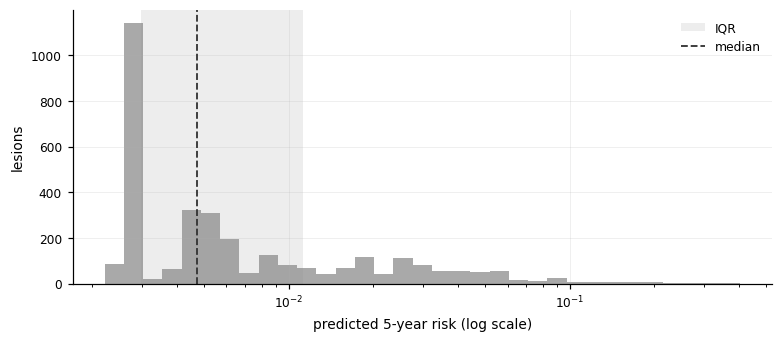

In [31]:
# ---- Figure F: the apparent risk distribution --------------------------------
_bins = np.logspace(np.log10(max(_r5.min(), 1e-4)), np.log10(_r5.max()), 34)
_ap_color = CONFIG["palette_validation"][0]

fig, ax = plt.subplots(figsize=(CONFIG["figure_width_in"], 3.0), constrained_layout=True)
ax.hist(_r5, bins=_bins, color=_ap_color, alpha=0.75, lw=0)
ax.axvspan(RISK_DIST_SUMMARY["q1_pct"] / 100, RISK_DIST_SUMMARY["q3_pct"] / 100,
           color=_ap_color, alpha=0.15, lw=0, label="IQR")
ax.axvline(RISK_DIST_SUMMARY["median_pct"] / 100, color="0.2", ls="--", lw=1.2, label="median")
ax.set_xscale("log")
ax.set_xlabel(f"predicted {PRIMARY / DIV:.0f}-year risk (log scale)")
ax.set_ylabel("lesions")
ax.legend(loc="upper right", frameon=False)
_save(fig, "figF_risk_distribution")
plt.show()


In [7]:
# ---- Table 8: risk-distribution summary --------------------------------------
RISK_DIST_TABLE = pd.DataFrame([
    {"Statistic": "Median", "Value (%)": f"{RISK_DIST_SUMMARY['median_pct']:.2f}"},
    {"Statistic": "IQR (Q1-Q3)",
     "Value (%)": f"{RISK_DIST_SUMMARY['q1_pct']:.2f}-{RISK_DIST_SUMMARY['q3_pct']:.2f}"},
    {"Statistic": "Range (min-max)",
     "Value (%)": f"{RISK_DIST_SUMMARY['min_pct']:.2f}-{RISK_DIST_SUMMARY['max_pct']:.2f}"},
    {"Statistic": "Distinct values", "Value (%)": str(RISK_DIST_SUMMARY["n_distinct"])},
])
_save_table(
    RISK_DIST_TABLE, "table8_risk_distribution_summary",
    tex_caption=(f"Summary of the apparent {PRIMARY / DIV:.0f}-year predicted-risk "
                 f"distribution across {RISK_DIST_SUMMARY['n_patients']} patients."),
    tex_label="tab:risk-distribution-summary",
)
RISK_DIST_TABLE


,Statistic,Value (%)
0,Median,0.47
1,IQR (Q1-Q3),0.30-1.12
2,Range (min-max),0.22-40.31
3,Distinct values,213


## 3. Censoring-aware primitives

Everything downstream rests on two estimators, so both are defined here and both are
tested against a brute-force implementation before use.

**Kaplan-Meier with a log-log interval.** The observed side of every comparison. The
log-log (rather than linear) interval is what keeps the bound inside $[0, 1]$ when the
estimate sits within a rounding error of zero, which at these event counts is most bins.

**Jackknife pseudo-observations.** A smoother needs a per-patient outcome, and at a
5-year horizon a censored patient does not have one. The pseudo-observation replaces it
with

$$\theta_i(t) = n\,\hat F(t) - (n-1)\,\hat F^{(-i)}(t),$$

the patient's leverage on the cohort Kaplan-Meier, where $\hat F = 1 - \hat S$. These
average to $\hat F(t)$ exactly, are defined for censored and uncensored patients alike,
and can be regressed on predicted risk like an ordinary binary outcome (Andersen and
Perme 2010). Individual values are not probabilities — they run negative and above 1 —
but they are unbiased for the conditional risk given the covariates, which is what a
calibration curve needs.

Computing $\hat S^{(-i)}$ by 3228 refits per horizon would be slow; the implementation
below does it in one pass by noting that dropping patient $i$ subtracts one from the
risk set at every event time up to $T_i$ and, if $i$ was the event, one from that death
count. The assertion cell checks the shortcut against the literal leave-one-out loop.

In [8]:
# ---- Kaplan-Meier and pseudo-observations -----------------------------------
def km_table(time, event):
    """(event times, deaths, at risk, S) on the distinct event times only."""
    t = np.asarray(time, dtype=float)
    e = np.asarray(event, dtype=bool)
    ut = np.unique(t[e])
    if ut.size == 0:
        return ut, ut.copy(), ut.copy(), ut.copy()
    order = np.argsort(t, kind="mergesort")
    ts = t[order]
    n_at_risk = len(ts) - np.searchsorted(ts, ut, side="left")
    deaths = np.array([np.count_nonzero((t == u) & e) for u in ut], dtype=float)
    S = np.cumprod(1.0 - deaths / n_at_risk)
    return ut, deaths, n_at_risk.astype(float), S


def km_risk(time, event, t):
    """Point estimate of 1 - S(t)."""
    ut, _, _, S = km_table(time, event)
    if ut.size == 0 or t < ut[0]:
        return 0.0
    return float(1.0 - S[np.searchsorted(ut, t, side="right") - 1])


def km_risk_ci(time, event, t):
    """1 - S(t) with a Greenwood log-log confidence interval."""
    ut, d, n, S = km_table(time, event)
    keep = ut <= t
    if not keep.any():
        return 0.0, 0.0, 0.0
    d, n, S = d[keep], n[keep], S[keep]
    s = float(S[-1])
    if s <= 0.0 or s >= 1.0 or np.any(n <= d):
        return 1.0 - s, 1.0 - s, 1.0 - s
    var_ll = float(np.sum(d / (n * (n - d)))) / (np.log(s) ** 2)
    if not np.isfinite(var_ll) or var_ll <= 0.0:
        return 1.0 - s, 1.0 - s, 1.0 - s
    half = Z * np.sqrt(var_ll)
    return 1.0 - s, 1.0 - s ** np.exp(-half), 1.0 - s ** np.exp(half)


def km_risk_curve(time, event, grid):
    """1 - S(t) with a log-log band, evaluated on `grid`."""
    ut, d, n, S = km_table(time, event)
    grid = np.asarray(grid, dtype=float)
    if ut.size == 0:
        z = np.zeros_like(grid)
        return z, z.copy(), z.copy()
    idx = np.searchsorted(ut, grid, side="right") - 1
    before = idx < 0
    idx = np.clip(idx, 0, None)
    s = S[idx]
    cum = np.cumsum(d / (n * np.maximum(n - d, 1e-12)))[idx]
    with np.errstate(divide="ignore", invalid="ignore"):
        half = Z * np.sqrt(cum) / np.abs(np.log(np.clip(s, 1e-12, 1 - 1e-12)))
        lo = 1.0 - s ** np.exp(-half)
        hi = 1.0 - s ** np.exp(half)
    risk = 1.0 - s
    bad = ~np.isfinite(lo) | ~np.isfinite(hi) | (s >= 1.0) | (s <= 0.0)
    lo = np.where(bad, risk, lo)
    hi = np.where(bad, risk, hi)
    for arr in (risk, lo, hi):
        arr[before] = 0.0
    return risk, np.clip(lo, 0, 1), np.clip(hi, 0, 1)


def pseudo_observations(time, event, t):
    """Jackknife pseudo-observations for the cumulative incidence 1 - S(t).

    One pass rather than n leave-one-out refits: with A_k = log(1 - d_k/n_k) the
    full contribution of event time k, dropping patient i replaces A_k by
    log(1 - d_k/(n_k - 1)) for every k with tau_k <= T_i, and additionally by
    log(1 - (d_k - 1)/(n_k - 1)) at the patient's own event time.
    """
    time = np.asarray(time, dtype=float)
    event = np.asarray(event, dtype=bool)
    n_obs = time.size
    ut, d, n, _ = km_table(time, event)
    keep = ut <= t
    ut, d, n = ut[keep], d[keep], n[keep]
    if ut.size == 0:
        return np.zeros(n_obs)

    A = np.log1p(-d / n)
    B = np.log1p(-d / (n - 1.0))
    with np.errstate(divide="ignore", invalid="ignore"):
        C = np.log1p(-(d - 1.0) / (n - 1.0))     # -inf when d == n, handled below
    cum_A = np.concatenate([[0.0], np.cumsum(A)])
    cum_B = np.concatenate([[0.0], np.cumsum(B)])

    k = np.searchsorted(ut, np.minimum(time, t), side="right")
    log_S_loo = cum_B[k] + (cum_A[-1] - cum_A[k])

    j = np.searchsorted(ut, time)
    j_safe = np.minimum(j, ut.size - 1)
    own_event = event & (j < ut.size) & (ut[j_safe] == time)
    log_S_loo = np.where(own_event, log_S_loo + (C - B)[j_safe], log_S_loo)

    S_loo = np.exp(log_S_loo)
    S_all = np.exp(cum_A[-1])
    return n_obs * (1.0 - S_all) - (n_obs - 1) * (1.0 - S_loo)

In [9]:
# ---- Assertions: the fast primitives against brute force --------------------
_rng = np.random.default_rng(CONFIG["random_seed"])
_sub = _rng.choice(N_PATIENTS, 400, replace=False)
_t, _e = TIME[_sub], EVENT[_sub]

for _h in (365.0, PRIMARY):
    _fast = pseudo_observations(_t, _e, _h)
    _n = _t.size
    _F = km_risk(_t, _e, _h)
    _brute = np.array([
        _n * _F - (_n - 1) * km_risk(np.delete(_t, i), np.delete(_e, i), _h)
        for i in range(_n)
    ])
    _err = float(np.abs(_fast - _brute).max())
    print(f"pseudo-observations, t={_h:5.0f} d : max |vectorised - leave-one-out| = {_err:.2e}")
    assert _err < 1e-9

for _h in HORIZONS:
    _ps = pseudo_observations(TIME, EVENT, _h)
    _F = km_risk(TIME, EVENT, _h)
    assert np.isclose(_ps.mean(), _F, atol=1e-12), "pseudo-observations must average to 1 - S(t)"
    print(f"full cohort,          t={_h:5.0f} d : mean pseudo-obs {_ps.mean():.6f} "
          f"= 1 - KM {_F:.6f}   [range {_ps.min():+.3f}, {_ps.max():+.3f}]")

# km_risk_curve on the grid must agree with the scalar estimator at the horizons.
_c, _lo, _hi = km_risk_curve(TIME, EVENT, HORIZONS)
for _i, _h in enumerate(HORIZONS):
    _p, _l, _u = km_risk_ci(TIME, EVENT, _h)
    assert np.allclose([_c[_i], _lo[_i], _hi[_i]], [_p, _l, _u], atol=1e-12)
print("km_risk_curve agrees with km_risk_ci at every horizon")

PSEUDO = {float(h): pseudo_observations(TIME, EVENT, float(h)) for h in HORIZONS}

pseudo-observations, t=  365 d : max |vectorised - leave-one-out| = 0.00e+00
pseudo-observations, t= 1825 d : max |vectorised - leave-one-out| = 4.44e-14
full cohort,          t=  365 d : mean pseudo-obs 0.001585 = 1 - KM 0.001585   [range -0.000, +1.049]
full cohort,          t=  730 d : mean pseudo-obs 0.003442 = 1 - KM 0.003442   [range -0.000, +1.342]
full cohort,          t= 1095 d : mean pseudo-obs 0.006183 = 1 - KM 0.006183   [range -0.002, +1.566]
full cohort,          t= 1460 d : mean pseudo-obs 0.009525 = 1 - KM 0.009525   [range -0.004, +1.992]
full cohort,          t= 1825 d : mean pseudo-obs 0.013373 = 1 - KM 0.013373   [range -0.010, +2.674]
km_risk_curve agrees with km_risk_ci at every horizon


## 4. The three calibration estimators

**Grouped.** Split the cohort into `n_risk_groups` equal-sized bands of predicted risk;
plot mean predicted against $1 - \hat S(t)$ within the band. Coarse, but it is the only
part of the figure that involves no smoothing choice, and its confidence intervals are
the honest picture of how much the 27 events can say.

**Smooth.** LOESS of the pseudo-observations on the predicted risk. The regression runs
in **complementary log-log space**, $\log(-\log(1 - p))$, not on the raw risk: 99% of
patients sit below 12% predicted risk while the maximum is near 40%, so on the raw scale
a LOESS neighbourhood at the top of the range spans almost the whole cohort and the
fitted tail is an extrapolation. On the cloglog scale the neighbourhoods are comparable
along the range. Set `CONFIG["loess_space"] = "risk"` to see the difference.

From the smooth curve come **ICI**, **E50**, **E90** and **Emax** — the mean, median,
90th percentile and maximum of $|\text{smoothed observed} - \text{predicted}|$ across
patients (Austin, Harrell and van Klaveren 2020). They are absolute risk differences, so
at a mean 5-year risk near 1% a "small" ICI of 0.002 is a fifth of the mean; the tables
report ICI both absolutely and as a fraction of the observed risk.

**Calibration in the large and slope.** Observed-over-expected is the cohort
Kaplan-Meier risk divided by the mean predicted risk. The slope is the coefficient of a
univariate Cox model on the linear predictor, with the outcome censored at the horizon.
A slope above 1 says the predicted risks are spread too narrowly — under-dispersed,
over-shrunk — and below 1 says the reverse.

In [10]:
# ---- Grouped, smooth and summary calibration estimators ---------------------
_EPS = 1e-12


def _to_loess_space(risk):
    if CONFIG["loess_space"] == "cloglog":
        return np.log(-np.log(np.clip(1.0 - np.asarray(risk, float), _EPS, 1.0 - _EPS)))
    return np.asarray(risk, float)


def grouped_calibration(risk, time, event, t, n_groups=None):
    """Equal-sized predicted-risk bands: mean predicted vs 1 - S(t) within band."""
    n_groups = CONFIG["n_risk_groups"] if n_groups is None else n_groups
    risk = np.asarray(risk, float)
    bins = pd.qcut(risk, q=n_groups, labels=False, duplicates="drop")
    rows = []
    for g in np.unique(bins):
        m = bins == g
        obs, lo, hi = km_risk_ci(time[m], event[m], t)
        rows.append({
            "group": int(g) + 1, "n": int(m.sum()),
            "events": int(np.count_nonzero(event[m] & (time[m] <= t))),
            "pred_mean": float(risk[m].mean()),
            "pred_min": float(risk[m].min()), "pred_max": float(risk[m].max()),
            "obs": obs, "obs_lo": lo, "obs_hi": hi,
        })
    return pd.DataFrame(rows)


def smooth_calibration(risk, pseudo, grid=None):
    """LOESS of pseudo-observations on predicted risk.

    Returns (grid, smoothed observed on the grid, smoothed observed per patient).
    """
    risk = np.asarray(risk, float)
    x = _to_loess_space(risk)
    fit = lowess(np.asarray(pseudo, float), x, frac=CONFIG["loess_frac"],
                 it=0, return_sorted=True)
    xs, ys = fit[:, 0], fit[:, 1]
    per_patient = np.clip(np.interp(x, xs, ys), 0.0, 1.0)
    if grid is None:
        return risk, per_patient, per_patient
    on_grid = np.clip(np.interp(_to_loess_space(grid), xs, ys), 0.0, 1.0)
    return np.asarray(grid, float), on_grid, per_patient


def e_statistics(risk, smoothed):
    """ICI / E50 / E90 / Emax: absolute gap between smoothed observed and predicted."""
    gap = np.abs(np.asarray(smoothed, float) - np.asarray(risk, float))
    return {"ICI": float(gap.mean()), "E50": float(np.median(gap)),
            "E90": float(np.quantile(gap, 0.90)), "Emax": float(gap.max())}


def calibration_slope(lp, time, event, t):
    """Cox coefficient on the linear predictor, outcome censored at t."""
    df = pd.DataFrame({"lp": np.asarray(lp, float),
                       "T": np.minimum(np.asarray(time, float), t),
                       "E": (np.asarray(event, bool) & (np.asarray(time, float) <= t)).astype(int)})
    if df["E"].sum() < 2:
        return np.nan, np.nan, np.nan
    try:
        cph = CoxPHFitter().fit(df, duration_col="T", event_col="E")
    except Exception:
        return np.nan, np.nan, np.nan
    ci = cph.confidence_intervals_.loc["lp"].to_numpy(dtype=float)
    return float(cph.params_["lp"]), float(ci[0]), float(ci[1])


def calibration_summary(risk, lp, time, event, t, pseudo=None):
    """Every scalar calibration statistic for one (prediction set, horizon)."""
    risk = np.asarray(risk, float)
    pseudo = pseudo_observations(time, event, t) if pseudo is None else pseudo
    obs, obs_lo, obs_hi = km_risk_ci(time, event, t)
    _, _, smoothed = smooth_calibration(risk, pseudo)
    slope, slope_lo, slope_hi = calibration_slope(lp, time, event, t)
    out = {
        "n": int(risk.size),
        "events": int(np.count_nonzero(np.asarray(event, bool) & (np.asarray(time, float) <= t))),
        "observed": obs, "observed_lo": obs_lo, "observed_hi": obs_hi,
        "predicted": float(risk.mean()),
        "OE": float(obs / risk.mean()) if risk.mean() > 0 else np.nan,
        "slope": slope, "slope_lo": slope_lo, "slope_hi": slope_hi,
    }
    out.update(e_statistics(risk, smoothed))
    out["ICI_rel"] = out["ICI"] / obs if obs > 0 else np.nan
    return out


print(f"LOESS: frac={CONFIG['loess_frac']} in {CONFIG['loess_space']} space; "
      f"{CONFIG['n_risk_groups']} risk groups; {CONFIG['n_bootstrap']} bootstrap replicates")

LOESS: frac=0.5 in cloglog space; 4 risk groups; 500 bootstrap replicates


## 5. Internal validation: the event-stratified bootstrap

Tuning this model used repeated stratified cross-validation because a grid search has to
fit thousands of models and CV is the cheap way to rank them. Nothing is *reported* from
CV. A reported metric in this repo comes from the stratified bootstrap:
`functions.repeated_cv.subsampling_bootstrap_optimism_grid_search`, run at
`n_bootstraps=500` in `cox.ipynb`, and the in-bag/out-of-bag replicate loop in
`threshold_2.0_copy.ipynb`. This section is that machinery pointed at calibration.

One replicate:

1. draw 3228 in-bag rows with replacement, **stratified on the event indicator** so the
   replicate carries all 27 events - an unstratified draw lands as low as 15, and a
   calibration curve estimated from 15 events is noise;
2. refit the min-max scaler and the Coxnet on those in-bag rows only, at the deployed
   hyperparameters - nothing is reselected;
3. score the whole cohort once with that fit. The in-bag rows are an index into the
   cohort and the out-of-bag rows are its complement, so one prediction pass serves all
   three evaluations.

| evaluation | fitted on | scored on | what it is |
|---|---|---|---|
| in-bag | the replicate | the same replicate | the apparent estimator, recomputed on a resample |
| out-of-bag | the replicate | the ~37% of patients it never saw | honest, on unseen patients |
| test | the replicate | the original 3228 | step C of the Efron-Harrell optimism bootstrap |

Every table below therefore carries three rows per horizon:

- **apparent** - the section-2 fit, with a 95% interval taken from the spread of the
  in-bag replicates, which is the bootstrap distribution of that same estimator;
- **out-of-bag** - the median across replicates of the statistic computed on that
  replicate's held-out patients, with a 2.5-97.5 percentile band. About 10 of the 27
  events land out of bag in any one replicate, so a single replicate says little; 500 of
  them say how much;
- **optimism-corrected** - apparent minus the mean of (in-bag - test), the correction
  `cox.ipynb` reports as `c_final`, with the percentile band of the optimism itself.

The last two answer the same question by different routes and are reported side by side.
Where they disagree, the disagreement is the honest uncertainty at 27 events.

One caveat that the table restates: ICI, E50, E90 and Emax are means of *absolute*
deviations. They cannot go below zero and they grow with noise, so a resample - which
fits a wobblier curve than the full cohort does - produces larger ones on average. Their
apparent interval can therefore sit entirely above the apparent value, and subtracting
an optimism can push the corrected value below zero. For those four, read the
out-of-bag row. O/E, the calibration slope and the C-index behave, and their corrected
values are the headline.

In [11]:
# ---- One bootstrap replicate ------------------------------------------------
# Everything a replicate reports is read off ONE fit, three ways.
KINDS = ("in-bag", "out-of-bag") + (("test",) if CONFIG["compute_optimism"] else ())

# Curves are read on a grid of PREDICTED RISK fixed by the apparent fit and shared by
# every replicate and every kind. Only a common x-axis lets the curves be averaged and
# subtracted point by point, which is what the optimism correction does.
CURVE_GRIDS = {
    float(h): np.unique(np.quantile(
        RISK_APPARENT[:, HZ_IDX[int(np.flatnonzero(HORIZONS == h)[0])]],
        np.linspace(0.0, 1.0, CONFIG["curve_grid_points"])))
    for h in PLOT_HORIZONS
}

# Brier grid: from the first observed recurrence - before it the Kaplan-Meier reference
# scores exactly zero and IPA is 0/0 - to the primary horizon.
FIRST_EVENT = float(TIME[EVENT].min())
BS_MASK = (EVAL_TIMES >= FIRST_EVENT) & (EVAL_TIMES <= PRIMARY)
BS_TIMES = EVAL_TIMES[BS_MASK]
BS_IDX = np.flatnonzero(BS_MASK)


def bootstrap_indices(rng, event, stratify_on_event):
    """In-bag row indices, size n, drawn with replacement.

    Stratifying on the event indicator keeps the number of events in every replicate
    equal to the cohort's 27; an unstratified draw lands as low as 15. Same rule, and
    the same reason, as the bootstrap in `threshold_2.0_copy.ipynb`.
    """
    n = int(event.size)
    if not stratify_on_event:
        return rng.choice(n, size=n, replace=True)
    event_rows = np.flatnonzero(event)
    censored_rows = np.flatnonzero(~event)
    return np.concatenate([
        rng.choice(event_rows, size=event_rows.size, replace=True),
        rng.choice(censored_rows, size=censored_rows.size, replace=True),
    ])


def oob_brier(inbag, oob, risk_oob):
    """Out-of-bag Brier score for the model and for a Kaplan-Meier null.

    The null is refitted in-bag and scored out-of-bag exactly like the model, so the
    IPA built from the two compares like with like. Times the out-of-bag follow-up
    cannot support come back NaN rather than raising; the cohort is administratively
    censored at the cap, so in practice every replicate covers the whole grid.
    """
    t_oob = TIME[oob]
    ok = (BS_TIMES >= t_oob.min()) & (BS_TIMES < t_oob.max())
    bs_model = np.full(BS_TIMES.size, np.nan)
    bs_null = np.full(BS_TIMES.size, np.nan)
    if ok.any():
        times = BS_TIMES[ok]
        s_km = np.array([1.0 - km_risk(TIME[inbag], EVENT[inbag], t) for t in times])
        bs_model[ok] = brier_score(y[inbag], y[oob], 1.0 - risk_oob[:, BS_IDX[ok]], times)[1]
        bs_null[ok] = brier_score(y[inbag], y[oob], np.tile(s_km, (oob.size, 1)), times)[1]
    return bs_model, bs_null


def run_replicate(replicate_index, seed):
    """One replicate. Never raises: a degenerate fit comes back with ok=False and its
    reason, so the failure rate is reported rather than silently absorbed."""
    started = time.perf_counter()
    for cat in QUIET_WARNINGS:          # this is a worker process; filters do not carry
        warnings.filterwarnings("ignore", category=cat)
    try:
        rng = np.random.default_rng(seed)
        inbag = bootstrap_indices(rng, EVENT, CONFIG["stratify_on_event"])
        oob = np.setdiff1d(np.arange(N_PATIENTS), np.unique(inbag), assume_unique=True)
        n_oob_events = int(EVENT[oob].sum())
        if n_oob_events < CONFIG["min_oob_events"]:
            raise ValueError(f"{n_oob_events} out-of-bag events, below "
                             f"CONFIG['min_oob_events'] = {CONFIG['min_oob_events']}")

        # The L1 path diverges on a small minority of resamples: coefficients reach
        # 1e6, exp(linear predictor) overflows and the Breslow baseline comes back NaN
        # for some or all patients. numpy's own overflow notices are silenced here
        # because the divergence is detected explicitly on the next lines and counted
        # as a failed replicate.
        with np.errstate(over="ignore", invalid="ignore"):
            lp, risk, n_nonzero, _, _ = fit_and_score(
                data_x.iloc[inbag], y[inbag], data_x, EVAL_TIMES)

        # A NaN survival curve would otherwise reach the LOESS as a missing outcome and
        # the pooled out-of-bag risk as a NaN, which is why finiteness is tested on the
        # WHOLE risk matrix and not only on the linear predictor: a fit that diverged
        # for a subset of patients leaves lp finite and the risk spread non-zero, and
        # used to sail through both.
        n_bad_rows = int(np.count_nonzero(~np.isfinite(risk).all(axis=1)))
        if not np.all(np.isfinite(lp)) or n_bad_rows:
            raise ValueError(
                f"the L1 path diverged: {int((~np.isfinite(lp)).sum())} non-finite "
                f"linear predictors, {n_bad_rows} rows with a non-finite survival curve")
        if float(np.ptp(risk[:, HZ_IDX[-1]])) <= 0.0:
            raise ValueError("degenerate risk matrix (the L1 path diverged)")

        rows = {"in-bag": inbag, "out-of-bag": oob, "test": np.arange(N_PATIENTS)}
        summaries, curves, c_index = [], {}, {}
        for kind in KINDS:
            r = rows[kind]
            t_k, e_k, lp_k = TIME[r], EVENT[r], lp[r]
            c_index[kind] = float(concordance_index_censored(e_k, t_k, lp_k)[0])
            for j, h in enumerate(HORIZONS):
                h = float(h)
                risk_k = risk[r, HZ_IDX[j]]
                # 'test' scores the original rows, so the cohort pseudo-observations
                # are the right ones and are already computed.
                ps = PSEUDO[h] if kind == "test" else pseudo_observations(t_k, e_k, h)
                s = calibration_summary(risk_k, lp_k, t_k, e_k, h, ps)
                s.update(replicate=replicate_index, kind=kind, horizon=h)
                summaries.append(s)
                if h in PLOT_SET:
                    curves[(kind, h)] = smooth_calibration(
                        risk_k, ps, grid=CURVE_GRIDS[h])[1].astype(np.float32)

        # How many held-out events have happened by each grid time. The Brier score is
        # scoring nothing before the first of them, and IPA is 0/0 there.
        oob_events_curve = np.array(
            [int(np.count_nonzero(EVENT[oob] & (TIME[oob] <= t))) for t in BS_TIMES],
            dtype=np.int32)

        try:
            bs_model, bs_null = oob_brier(inbag, oob, risk[oob])
            brier_error = ""
        except Exception as exc:
            # A Brier score that will not evaluate is not a reason to throw the
            # replicate's calibration away; it is recorded and reported as NaN.
            bs_model = np.full(BS_TIMES.size, np.nan)
            bs_null = np.full(BS_TIMES.size, np.nan)
            brier_error = f"{type(exc).__name__}: {exc}"

        return {
            "ok": True, "replicate": replicate_index, "seed": seed,
            "n_inbag_unique": int(np.unique(inbag).size), "n_oob": int(oob.size),
            "n_oob_events": n_oob_events, "n_nonzero_coef": int(n_nonzero),
            # The spread of this replicate's own out-of-bag predictions, which is what
            # sets the best Brier score attainable at that spread (see the IBS cell).
            "var_risk_oob_primary": float(np.var(risk[oob, HZ_IDX[-1]])),
            "oob_rows": oob.astype(np.int32),
            "oob_risk": risk[oob].astype(np.float32),
            "oob_lp": lp[oob].astype(np.float32),
            "summaries": summaries, "curves": curves, "c_index": c_index,
            "bs_model": bs_model, "bs_null": bs_null, "brier_error": brier_error,
            "oob_events_curve": oob_events_curve,
            "seconds": time.perf_counter() - started,
        }
    except Exception as exc:
        return {"ok": False, "replicate": replicate_index, "seed": seed,
                "error": f"{type(exc).__name__}: {exc}",
                "traceback": traceback.format_exc(),
                "seconds": time.perf_counter() - started}


print(f"kinds evaluated per replicate : {', '.join(KINDS)}")
print(f"curve grid                    : {CONFIG['curve_grid_points']} points at "
      f"{', '.join(f'{h / DIV:.0f}y' for h in PLOT_HORIZONS)}")
print(f"Brier grid                    : {BS_TIMES.size} points, "
      f"{BS_TIMES[0]:.0f}-{BS_TIMES[-1]:.0f} d (first event at {FIRST_EVENT:.0f} d)")

kinds evaluated per replicate : in-bag, out-of-bag, test
curve grid                    : 400 points at 1y, 3y, 5y
Brier grid                    : 121 points, 75-1825 d (first event at 75 d)


In [12]:
# ---- Run the bootstrap ------------------------------------------------------
B = int(CONFIG["n_bootstrap"])
SEEDS = [int(s.generate_state(1)[0]) for s in
         np.random.SeedSequence(CONFIG["bootstrap_seed"]).spawn(B)]

OOB_RISK_SUM = np.zeros((N_PATIENTS, EVAL_TIMES.size))
OOB_LP_SUM = np.zeros(N_PATIENTS)
OOB_COUNT = np.zeros(N_PATIENTS)
# _bs_model, _bs_null, _var_oob and _curves are filled in ARRIVAL order (the loop is
# unordered) and are only ever reduced down the replicate axis, so they stay aligned
# with each other; REPLICATE_LOG is sorted separately for reading.
_summaries, _curves, _bs_model, _bs_null, _var_oob, _ev_oob = [], [], [], [], [], []
_log, _c_rows, _failed = [], [], []

print(f"running {B} replicates on n_jobs={CONFIG['n_jobs']} "
      f"(master seed {CONFIG['bootstrap_seed']})")
_t0 = time.perf_counter()
_done = 0
# Each payload carries one out-of-bag risk matrix (~1200 x 125 float32). They are
# folded into the running sums as they arrive, so only a few are ever in memory.
_parallel = Parallel(n_jobs=CONFIG["n_jobs"], return_as="generator_unordered")
for _p in _parallel(delayed(run_replicate)(_b, SEEDS[_b]) for _b in range(B)):
    _done += 1
    if _p["ok"]:
        _rows = _p["oob_rows"]
        OOB_RISK_SUM[_rows] += _p["oob_risk"]
        OOB_LP_SUM[_rows] += _p["oob_lp"]
        OOB_COUNT[_rows] += 1.0
        _summaries.extend(_p["summaries"])
        _curves.append(_p["curves"])
        _bs_model.append(_p["bs_model"])
        _bs_null.append(_p["bs_null"])
        _var_oob.append(_p["var_risk_oob_primary"])
        _ev_oob.append(_p["oob_events_curve"])
        _c_rows.append(dict(replicate=_p["replicate"], **_p["c_index"]))
        _log.append({k: _p[k] for k in ("replicate", "seed", "n_inbag_unique", "n_oob",
                                        "n_oob_events", "n_nonzero_coef",
                                        "var_risk_oob_primary", "seconds",
                                        "brier_error")})
    else:
        _failed.append(_p)
    if _done % CONFIG["progress_every"] == 0 or _done == B:
        _el = time.perf_counter() - _t0
        print(f"  {_done:>4d}/{B}   elapsed {_el / 60:.1f} min   "
              f"ETA {_el / _done * (B - _done) / 60:.1f} min", flush=True)

N_OK = len(_log)
if N_OK == 0:
    raise RuntimeError("every replicate failed - nothing to aggregate")

REPLICATE_LOG = pd.DataFrame(_log).sort_values("replicate").reset_index(drop=True)
BOOT_PER_REPLICATE = pd.DataFrame(_summaries)
C_PER_REPLICATE = pd.DataFrame(_c_rows).sort_values("replicate").reset_index(drop=True)
FAILURES = (pd.DataFrame([{k: f[k] for k in ("replicate", "seed", "error", "traceback")}
                          for f in _failed])
            if _failed else
            pd.DataFrame(columns=["replicate", "seed", "error", "traceback"]))

print(f"\nfinished in {(time.perf_counter() - _t0) / 60:.1f} min")
print(f"successful replicates : {N_OK}/{B}")
print(f"degenerate replicates : {len(_failed)}/{B} ({100.0 * len(_failed) / B:.1f}%)")
if _failed:
    # A high failure rate is itself a finding about the stability of the fit.
    for _msg, _cnt in pd.Series([f["error"] for f in _failed]).value_counts().items():
        print(f"    {_cnt:>4d}x  {_msg}")
    if len(_failed) / B > 0.10:
        print(f"  WARNING: {100.0 * len(_failed) / B:.0f}% of replicates failed, so the "
              f"surviving {N_OK} are the subset on which this fit happens to converge "
              f"and are NOT a random sample of resamples. Report the failure rate "
              f"alongside every number below.")

_ns = REPLICATE_LOG["n_oob"].to_numpy(float)
_ne = REPLICATE_LOG["n_oob_events"].to_numpy(float)
print(f"\nout-of-bag rows       : mean {_ns.mean():.0f} ({_ns.min():.0f}-{_ns.max():.0f}), "
      f"{100 * _ns.mean() / N_PATIENTS:.1f}% of the cohort")
print(f"out-of-bag events     : mean {_ne.mean():.1f} ({_ne.min():.0f}-{_ne.max():.0f}) "
      f"of {int(EVENT.sum())}")
print(f"non-zero coefficients : median {REPLICATE_LOG['n_nonzero_coef'].median():.0f} "
      f"({REPLICATE_LOG['n_nonzero_coef'].min()}-{REPLICATE_LOG['n_nonzero_coef'].max()})"
      f" of {data_x.shape[1]}   (apparent {N_NONZERO})")
_bad_brier = REPLICATE_LOG.loc[REPLICATE_LOG["brier_error"] != "", "brier_error"]
if len(_bad_brier):
    print(f"replicates whose out-of-bag Brier score failed: {len(_bad_brier)} of {N_OK} "
          f"(their calibration is kept; the Brier curve is NaN)")
    for _msg, _cnt in _bad_brier.value_counts().items():
        print(f"    {_cnt:>4d}x  {_msg}")

assert (OOB_COUNT > 0).all(), (
    f"{int((OOB_COUNT == 0).sum())} patients were never out of bag - raise "
    f"CONFIG['n_bootstrap'] (at 500 the chance of this is ~1e-100)")
RISK_OOB = OOB_RISK_SUM / OOB_COUNT[:, None]
LP_OOB = OOB_LP_SUM / OOB_COUNT
print(f"\nper-patient out-of-bag predictions pooled over {OOB_COUNT.mean():.0f} replicates "
      f"({OOB_COUNT.min():.0f}-{OOB_COUNT.max():.0f})")
print("  the pooled vector is used for the FIGURES only. Every reported number is")
print("  computed inside a replicate and then aggregated, because pooling shrinks the")
print("  spread of the predictions and would flatter the slope.")

# Discrimination, the same three ways. The corrected value is exactly the c_final that
# cox.ipynb reports from subsampling_bootstrap_optimism_grid_search.
_c_oob = C_PER_REPLICATE["out-of-bag"].to_numpy(float)
DISCRIMINATION = {
    "c_apparent": float(C_APPARENT),
    "c_apparent_ipcw": float(C_APPARENT_IPCW),
    "c_oob_median": float(np.median(_c_oob)),
    "c_oob_lo": float(np.percentile(_c_oob, PLO)),
    "c_oob_hi": float(np.percentile(_c_oob, PHI)),
}
if CONFIG["compute_optimism"]:
    _opt = (C_PER_REPLICATE["in-bag"].to_numpy(float)
            - C_PER_REPLICATE["test"].to_numpy(float))
    DISCRIMINATION.update(
        c_inbag_mean=float(C_PER_REPLICATE["in-bag"].mean()),
        c_test_mean=float(C_PER_REPLICATE["test"].mean()),
        c_optimism=float(_opt.mean()),
        c_final=float(C_APPARENT - _opt.mean()),
        c_final_lo=float(C_APPARENT - np.percentile(_opt, PHI)),
        c_final_hi=float(C_APPARENT - np.percentile(_opt, PLO)),
    )
print(f"\nC-index   apparent           {DISCRIMINATION['c_apparent']:.4f}")
print(f"C-index   apparent (IPCW)    {DISCRIMINATION['c_apparent_ipcw']:.4f}")
print(f"          out-of-bag         {DISCRIMINATION['c_oob_median']:.4f} "
      f"[{DISCRIMINATION['c_oob_lo']:.4f}, {DISCRIMINATION['c_oob_hi']:.4f}]")
if CONFIG["compute_optimism"]:
    print(f"          optimism           {DISCRIMINATION['c_optimism']:+.4f}   "
          f"(in-bag {DISCRIMINATION['c_inbag_mean']:.4f} - test "
          f"{DISCRIMINATION['c_test_mean']:.4f})")
    print(f"          optimism-corrected {DISCRIMINATION['c_final']:.4f} "
          f"[{DISCRIMINATION['c_final_lo']:.4f}, {DISCRIMINATION['c_final_hi']:.4f}]"
          f"   <- cox.ipynb's c_final")

running 500 replicates on n_jobs=-1 (master seed 202608)
    25/500   elapsed 0.6 min   ETA 10.9 min
    50/500   elapsed 0.9 min   ETA 8.0 min
    75/500   elapsed 1.3 min   ETA 7.3 min
   100/500   elapsed 1.6 min   ETA 6.5 min
   125/500   elapsed 1.9 min   ETA 5.8 min
   150/500   elapsed 2.2 min   ETA 5.2 min
   175/500   elapsed 2.6 min   ETA 4.7 min
   200/500   elapsed 2.9 min   ETA 4.3 min
   225/500   elapsed 3.2 min   ETA 3.9 min
   250/500   elapsed 3.5 min   ETA 3.5 min
   275/500   elapsed 3.9 min   ETA 3.2 min
   300/500   elapsed 4.2 min   ETA 2.8 min
   325/500   elapsed 4.5 min   ETA 2.4 min
   350/500   elapsed 4.8 min   ETA 2.1 min
   375/500   elapsed 5.1 min   ETA 1.7 min
   400/500   elapsed 5.4 min   ETA 1.3 min
   425/500   elapsed 5.7 min   ETA 1.0 min
   450/500   elapsed 6.0 min   ETA 0.7 min
   475/500   elapsed 6.3 min   ETA 0.3 min
   500/500   elapsed 6.6 min   ETA 0.0 min

finished in 6.6 min
successful replicates : 495/500
degenerate replicates : 5/500

In [13]:
# ---- Table 1: calibration at each horizon, three ways -----------------------
# apparent            the full-cohort fit; the interval is the 2.5-97.5 spread of the
#                     in-bag replicates, the bootstrap distribution of that estimator
# out-of-bag          median over replicates of the statistic computed on that
#                     replicate's held-out patients; interval = percentile band
# optimism-corrected  apparent - mean(in-bag - test); the interval carries the
#                     percentile band of the optimism itself
STAT_COLS = ["predicted", "OE", "slope", "ICI", "E50", "E90", "Emax", "ICI_rel"]

APPARENT_SUMMARY, _rows = {}, []
_t0 = time.time()
for _j, _h in enumerate(HORIZONS):
    _h = float(_h)
    _ap = calibration_summary(RISK_APPARENT[:, HZ_IDX[_j]], LP_APPARENT,
                              TIME, EVENT, _h, PSEUDO[_h])
    APPARENT_SUMMARY[_h] = _ap
    _kind_df = {k: BOOT_PER_REPLICATE[(BOOT_PER_REPLICATE["kind"] == k)
                                      & (BOOT_PER_REPLICATE["horizon"] == _h)]
                for k in KINDS}
    # The observed column is a property of the cohort, not of the model, so it is the
    # cohort Kaplan-Meier in every row. Only the out-of-bag O/E is formed inside the
    # replicate, against that replicate's own held-out Kaplan-Meier.
    _base = {"horizon": _h, "n": N_PATIENTS, "events": int(_ap["events"]),
             "observed": _ap["observed"], "observed_lo": _ap["observed_lo"],
             "observed_hi": _ap["observed_hi"], "n_replicates": N_OK}

    _r = dict(_base, validation="apparent")
    for _s in STAT_COLS:
        _r[_s] = float(_ap[_s])
        _r[_s + "_lo"], _r[_s + "_hi"] = np.nanpercentile(
            _kind_df["in-bag"][_s].to_numpy(float), [PLO, PHI])
    _rows.append(_r)

    _oob = _kind_df["out-of-bag"]
    _r = dict(_base, validation="out-of-bag",
              observed_oob_median=float(np.nanmedian(_oob["observed"].to_numpy(float))),
              events_oob_median=float(np.nanmedian(_oob["events"].to_numpy(float))))
    for _s in STAT_COLS:
        _v = _oob[_s].to_numpy(float)
        _r[_s] = float(np.nanmedian(_v))
        _r[_s + "_lo"], _r[_s + "_hi"] = np.nanpercentile(_v, [PLO, PHI])
    _rows.append(_r)

    if CONFIG["compute_optimism"]:
        _r = dict(_base, validation="optimism-corrected")
        for _s in STAT_COLS:
            _o = (_kind_df["in-bag"][_s].to_numpy(float)
                  - _kind_df["test"][_s].to_numpy(float))
            _r[_s] = float(_ap[_s] - np.nanmean(_o))
            _r[_s + "_lo"] = float(_ap[_s] - np.nanpercentile(_o, PHI))
            _r[_s + "_hi"] = float(_ap[_s] - np.nanpercentile(_o, PLO))
            _r[_s + "_optimism"] = float(np.nanmean(_o))
        _rows.append(_r)

CALIBRATION_TABLE = pd.DataFrame(_rows)
CALIBRATION_TABLE["validation"] = pd.Categorical(
    CALIBRATION_TABLE["validation"],
    categories=["apparent", "out-of-bag", "optimism-corrected"], ordered=True)
CALIBRATION_TABLE = (CALIBRATION_TABLE.sort_values(["horizon", "validation"])
                     .reset_index(drop=True))
print(f"assembled in {time.time() - _t0:.1f}s "
      f"({N_OK} replicates x {len(KINDS)} evaluations x {HORIZONS.size} horizons)\n")


def _pm(value, lo, hi, scale=1.0, digits=2):
    """'1.02 (0.71-1.47)' - a point estimate and its interval in one cell."""
    return f"{scale * value:.{digits}f} ({scale * lo:.{digits}f}-{scale * hi:.{digits}f})"


_fmt = CALIBRATION_TABLE.assign(
    years=lambda d: (d["horizon"] / DIV).round(0).astype(int),
    observed_pct=lambda d: [f"{100 * o:.2f} ({100 * l:.2f}-{100 * h:.2f})"
                            for o, l, h in zip(d.observed, d.observed_lo, d.observed_hi)],
    predicted_pct=lambda d: [_pm(v, l, h, 100, 2)
                             for v, l, h in zip(d.predicted, d.predicted_lo, d.predicted_hi)],
    OE_s=lambda d: [_pm(v, l, h, 1, 2) for v, l, h in zip(d.OE, d.OE_lo, d.OE_hi)],
    slope_s=lambda d: [_pm(v, l, h, 1, 2) for v, l, h in zip(d.slope, d.slope_lo, d.slope_hi)],
    ICI_pct=lambda d: [_pm(v, l, h, 100, 3) for v, l, h in zip(d.ICI, d.ICI_lo, d.ICI_hi)],
    E90_pct=lambda d: (100 * d["E90"]).round(3),
    ICI_rel_pct=lambda d: (100 * d["ICI_rel"]).round(1),
)[["years", "validation", "events", "observed_pct", "predicted_pct", "OE_s",
   "slope_s", "ICI_pct", "E90_pct", "ICI_rel_pct"]]
_fmt.columns = ["horizon (y)", "validation", "events", "observed % (95% CI)",
                "predicted %", "O/E", "slope", "ICI %", "E90 %", "ICI / observed %"]
pd.set_option("display.width", 220)
print(_fmt.to_string(index=False))
print(f"""
Intervals are 2.5-97.5 percentiles over the {N_OK} replicates: for the apparent row, of
the same statistic recomputed in-bag; for the out-of-bag row, of the statistic on the
held-out patients; for the corrected row, of the optimism itself. The events column is
the cohort count; roughly {REPLICATE_LOG['n_oob_events'].mean():.0f} of them land out of
bag in any one replicate.

Read the E-statistics (ICI, E50, E90, Emax) with that in mind. They are means of
ABSOLUTE deviations, so they cannot be negative and they grow with noise: a resample
fits a wobblier curve than the full cohort does, which is why the in-bag spread can sit
entirely above the apparent value and why subtracting the optimism can push the
corrected value below zero. Neither is a bug, and neither is a reason to quote the
apparent E-statistics - the out-of-bag row is the honest one for those columns. O/E, the
slope and the C-index are unbiased enough for the corrected column to be the headline,
which is the column cox.ipynb reports.""")

assembled in 0.7s (495 replicates x 3 evaluations x 5 horizons)

 horizon (y)         validation  events observed % (95% CI)      predicted %              O/E            slope                ICI %  E90 %  ICI / observed %
           1           apparent       5    0.16 (0.07-0.38) 0.16 (0.06-0.29) 1.00 (0.98-1.02) 1.69 (1.09-2.73)  0.115 (0.035-0.222)  0.177              72.8
           1         out-of-bag       5    0.16 (0.07-0.38) 0.15 (0.06-0.29) 1.01 (0.00-5.38) 1.25 (0.72-2.54)  0.150 (0.076-0.337)  0.365              91.8
           1 optimism-corrected       5    0.16 (0.07-0.38) 0.16 (0.14-0.17) 1.24 (0.55-2.63) 1.36 (0.47-2.05)  0.105 (0.007-0.217)  0.207              65.3
           2           apparent      10    0.34 (0.18-0.64) 0.34 (0.17-0.51) 1.01 (0.98-1.03) 2.09 (1.51-3.04)  0.286 (0.119-0.396)  0.352              83.1
           2         out-of-bag      10    0.34 (0.18-0.64) 0.33 (0.17-0.51) 1.01 (0.25-3.24) 1.55 (0.92-3.13)  0.261 (0.128-0.550)  0.519            

In [14]:
# ---- The calibration curves and their bands ---------------------------------
# All three live on the same x-grid (CURVE_GRIDS), which is what makes them
# comparable point by point:
#   apparent            the deployed fit's own curve; band = 2.5-97.5 percentiles of
#                       the in-bag replicate curves
#   out-of-bag          median of the replicate curves, each fitted in-bag and read on
#                       that replicate's held-out patients; band = their percentiles
#   optimism-corrected  apparent - mean(in-bag - test) pointwise: the same correction
#                       the table applies, drawn (Harrell's bias-corrected curve)
SMOOTH = {}
for _h in PLOT_HORIZONS:
    _h = float(_h)
    _j = int(np.flatnonzero(HORIZONS == _h)[0])
    _grid = CURVE_GRIDS[_h]
    _draws = {k: np.vstack([c[(k, _h)] for c in _curves]).astype(float) for k in KINDS}

    _apparent_curve = smooth_calibration(RISK_APPARENT[:, HZ_IDX[_j]], PSEUDO[_h],
                                         grid=_grid)[1]
    _ib_lo, _ib_hi = np.nanpercentile(_draws["in-bag"], [PLO, PHI], axis=0)
    _ob = _draws["out-of-bag"]
    _ob_lo, _ob_hi = np.nanpercentile(_ob, [PLO, PHI], axis=0)

    _entries = {
        "apparent": (_apparent_curve, _ib_lo, _ib_hi, RISK_APPARENT[:, HZ_IDX[_j]]),
        "out-of-bag": (np.nanmedian(_ob, axis=0), _ob_lo, _ob_hi, RISK_OOB[:, HZ_IDX[_j]]),
    }
    if CONFIG["compute_optimism"]:
        _opt = _draws["in-bag"] - _draws["test"]
        _entries["optimism-corrected"] = (
            _apparent_curve - np.nanmean(_opt, axis=0),
            _apparent_curve - np.nanpercentile(_opt, PHI, axis=0),
            _apparent_curve - np.nanpercentile(_opt, PLO, axis=0),
            RISK_APPARENT[:, HZ_IDX[_j]],
        )

    for _kind, (_curve, _lo, _hi, _risk) in _entries.items():
        _row = CALIBRATION_TABLE.query("horizon == @_h and validation == @_kind").iloc[0]
        SMOOTH[(_kind, _h)] = {
            "risk": _risk, "grid": _grid,
            "curve": np.clip(_curve, 0.0, 1.0),
            "band_lo": np.clip(_lo, 0.0, 1.0), "band_hi": np.clip(_hi, 0.0, 1.0),
            # The corrected curve is drawn on the apparent risks, so it carries the
            # apparent grouped points; only the smooth curve is corrected.
            "groups": grouped_calibration(_risk, TIME, EVENT, _h),
            "OE": float(_row["OE"]), "OE_lo": float(_row["OE_lo"]),
            "OE_hi": float(_row["OE_hi"]), "ICI": float(_row["ICI"]),
            "x_upper": float(np.quantile(_risk, CONFIG["plot_risk_upper_quantile"])),
            "x_max": float(_risk.max()),
        }

print(f"curves from {N_OK} replicates on {CURVE_GRIDS[PRIMARY].size} grid points")
for (_kind, _h), _d in sorted(SMOOTH.items(), key=lambda kv: (kv[0][1], kv[0][0])):
    print(f"  {_h / DIV:.0f}y {_kind:<19s} O/E {_d['OE']:.3f} "
          f"[{_d['OE_lo']:.3f}, {_d['OE_hi']:.3f}]   x-axis truncated at "
          f"{100 * _d['x_upper']:.1f}% (max {100 * _d['x_max']:.1f}%)")

# Cache the pieces Figure E needs so that cell can be rerun standalone (no bootstrap)
# after a kernel restart - editing that figure should not cost another run of this loop.
with open(os.path.join(OUTPUT_DIR, "_smooth_cache.pkl"), "wb") as _fh:
    pickle.dump({"CONFIG": CONFIG, "DIV": DIV, "PRIMARY": PRIMARY,
                 "SMOOTH": SMOOTH, "CALIBRATION_TABLE": CALIBRATION_TABLE}, _fh)

curves from 495 replicates on 132 grid points
  1y apparent            O/E 1.000 [0.981, 1.021]   x-axis truncated at 1.4% (max 5.9%)
  1y optimism-corrected  O/E 1.237 [0.555, 2.634]   x-axis truncated at 1.4% (max 5.9%)
  1y out-of-bag          O/E 1.013 [0.000, 5.384]   x-axis truncated at 1.6% (max 4.6%)
  3y apparent            O/E 1.003 [0.957, 1.033]   x-axis truncated at 5.5% (max 21.1%)
  3y optimism-corrected  O/E 1.037 [0.765, 1.439]   x-axis truncated at 5.5% (max 21.1%)
  3y out-of-bag          O/E 0.942 [0.416, 2.152]   x-axis truncated at 6.3% (max 15.9%)
  5y apparent            O/E 1.016 [0.934, 1.077]   x-axis truncated at 11.6% (max 40.3%)
  5y optimism-corrected  O/E 1.025 [0.889, 1.181]   x-axis truncated at 11.6% (max 40.3%)
  5y out-of-bag          O/E 0.988 [0.546, 1.488]   x-axis truncated at 12.9% (max 31.0%)


In [15]:
# ---- Brier score and the index of prediction accuracy over time -------------
# IPA = 1 - BS(model) / BS(Kaplan-Meier). It answers "how much of the squared error
# does knowing the covariates remove?", which at a 1% event rate is a far more
# readable number than the Brier score itself.
#
# Apparent: model and reference both fitted on the whole cohort and scored on it.
# Out-of-bag: BOTH the model and the Kaplan-Meier reference are refitted on the in-bag
# rows and scored on the held-out rows of that replicate, so the ratio compares like
# with like - a null that had seen the whole cohort would make the model look worse
# than it is.
_S_km = np.array([1.0 - km_risk(TIME, EVENT, t) for t in BS_TIMES])
_, BS_REFERENCE = brier_score(y, y, np.tile(_S_km, (N_PATIENTS, 1)), BS_TIMES)
_, BS_APPARENT = brier_score(y, y, 1.0 - RISK_APPARENT[:, BS_IDX], BS_TIMES)
assert np.all(BS_REFERENCE > 0), "IPA is undefined where the reference Brier score is 0"

BS_OOB_DRAWS = np.vstack(_bs_model)
BS_NULL_DRAWS = np.vstack(_bs_null)
EV_OOB_DRAWS = np.vstack(_ev_oob)

# Where IPA means anything. Before the held-out patients have accumulated events, both
# Brier scores are measuring the size of the predicted risks rather than their accuracy
# and the ratio is 0/0: at 75-180 days the median replicate has no out-of-bag event at
# all, and the raw IPA there swings to -300%. The cut is a function of TIME only - the
# median replicate's event count - so every replicate contributes at every time shown
# and no selection creeps in. The Brier scores themselves are reported over the whole
# grid; only their ratio is withheld.
_ev_median = np.median(EV_OOB_DRAWS, axis=0)
IPA_DEFINED = _ev_median >= CONFIG["ipa_min_oob_events"]
if not IPA_DEFINED.any():
    raise RuntimeError("no time point has enough out-of-bag events for IPA - lower "
                       "CONFIG['ipa_min_oob_events']")
IPA_START = float(BS_TIMES[int(np.argmax(IPA_DEFINED))])

IPA_APPARENT = np.where(IPA_DEFINED, 1.0 - BS_APPARENT / BS_REFERENCE, np.nan)
with np.errstate(divide="ignore", invalid="ignore"):
    IPA_OOB_DRAWS = 1.0 - BS_OOB_DRAWS / BS_NULL_DRAWS
IPA_OOB_DRAWS[~np.isfinite(IPA_OOB_DRAWS)] = np.nan
IPA_OOB_DRAWS[:, ~IPA_DEFINED] = np.nan


def _band(draws):
    """Median and percentile band down the replicate axis, NaNs ignored."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)   # all-NaN time points
        return (np.nanmedian(draws, axis=0),
                np.nanpercentile(draws, PLO, axis=0),
                np.nanpercentile(draws, PHI, axis=0))


BS_OOB, BS_OOB_LO, BS_OOB_HI = _band(BS_OOB_DRAWS)
BS_NULL_OOB = _band(BS_NULL_DRAWS)[0]
IPA_OOB, IPA_OOB_LO, IPA_OOB_HI = _band(IPA_OOB_DRAWS)

_cov = np.isfinite(BS_OOB_DRAWS).sum(axis=0)
print(f"out-of-bag Brier score: {_cov.min()}-{_cov.max()} of {N_OK} replicates "
      f"contribute per time point")
print(f"IPA reported from day {IPA_START:.0f} ({IPA_START / DIV:.1f} y), the first time "
      f"the median replicate\n  holds {CONFIG['ipa_min_oob_events']} out-of-bag events; "
      f"by 5 years it holds {_ev_median[-1]:.0f} of {int(EVENT.sum())}")

BRIER_TABLE = pd.DataFrame({
    "time_days": BS_TIMES,
    "brier_reference_km": BS_REFERENCE,
    "brier_apparent": BS_APPARENT,
    "brier_oob_median": BS_OOB, "brier_oob_lo": BS_OOB_LO, "brier_oob_hi": BS_OOB_HI,
    "brier_reference_oob_median": BS_NULL_OOB,
    "ipa_apparent": IPA_APPARENT,
    "ipa_oob_median": IPA_OOB, "ipa_oob_lo": IPA_OOB_LO, "ipa_oob_hi": IPA_OOB_HI,
    "oob_events_median": _ev_median,
    "n_replicates": _cov,
})

print("\nBrier score and IPA at the reporting horizons")
_show = BRIER_TABLE[BRIER_TABLE["time_days"].isin(HORIZONS)].copy()
_show["horizon (y)"] = (_show["time_days"] / DIV).round(0).astype(int)
print(_show[["horizon (y)", "brier_reference_km", "brier_apparent", "brier_oob_median",
             "ipa_apparent", "ipa_oob_median"]]
      .rename(columns={"brier_reference_km": "BS (KM)", "brier_apparent": "BS (apparent)",
                       "brier_oob_median": "BS (OOB)", "ipa_apparent": "IPA (apparent)",
                       "ipa_oob_median": "IPA (OOB)"})
      .to_string(index=False, float_format=lambda v: f"{v:.5f}"))

out-of-bag Brier score: 441-495 of 495 replicates contribute per time point
IPA reported from day 405 (1.1 y), the first time the median replicate
  holds 3 out-of-bag events; by 5 years it holds 10 of 27

Brier score and IPA at the reporting horizons
 horizon (y)  BS (KM)  BS (apparent)  BS (OOB)  IPA (apparent)  IPA (OOB)
           1  0.00158        0.00155   0.00168             NaN        NaN
           2  0.00343        0.00320   0.00331         0.06709    0.02843
           3  0.00615        0.00556   0.00555         0.09501    0.04918
           4  0.00944        0.00853   0.00878         0.09588    0.04287
           5  0.01320        0.01217   0.01242         0.07818    0.02606


In [16]:
# ---- Integrated Brier score over 0 to 5 years -------------------------------
# IBS(t*) = (1 / t*) * integral of BS(u) du from 0 to t*. It is the single number the
# thesis quotes: one summary of prediction error over the whole horizon rather than a
# curve to read off. BS(0) = 0 exactly - at day 0 every patient is event-free and every
# model predicts so - hence the curve is extended back to the origin instead of being
# integrated only over the grid it was evaluated on.
def _ibs(curve):
    """Integrate one Brier curve from 0 to the primary horizon.

    A replicate whose out-of-bag follow-up starts after the first few grid points has
    NaN there; those points are skipped and the trapezoid spans them from BS(0) = 0
    instead, which at the flat left end of the curve costs almost nothing. A replicate
    missing the RIGHT edge would be integrated over a shorter horizon and divided by
    the full one, so it is dropped instead.
    """
    c = np.asarray(curve, dtype=float)
    ok = np.isfinite(c)
    if not ok.any() or not ok[-1]:
        return np.nan
    t = np.concatenate([[0.0], BS_TIMES[ok]])
    v = np.concatenate([[0.0], c[ok]])
    return float(np.trapezoid(v, t) / float(BS_TIMES[-1]))


_ibs_model_all = np.array([_ibs(r) for r in BS_OOB_DRAWS])
_ibs_null_all = np.array([_ibs(r) for r in BS_NULL_DRAWS])
_complete = np.isfinite(_ibs_model_all) & np.isfinite(_ibs_null_all)
_ibs_model = _ibs_model_all[_complete]
_ibs_null = _ibs_null_all[_complete]
_ipa_int = 1.0 - _ibs_model / _ibs_null

IBS = {
    "horizon_days": float(PRIMARY),
    "ibs_reference_km": _ibs(BS_REFERENCE),
    "ibs_apparent": _ibs(BS_APPARENT),
    "n_replicates_integrated": int(_complete.sum()),
    "ibs_oob_median": float(np.median(_ibs_model)),
    "ibs_oob_lo": float(np.percentile(_ibs_model, PLO)),
    "ibs_oob_hi": float(np.percentile(_ibs_model, PHI)),
    "ibs_reference_oob_median": float(np.median(_ibs_null)),
}
IBS["ipa_integrated_apparent"] = 1.0 - IBS["ibs_apparent"] / IBS["ibs_reference_km"]
IBS["ipa_integrated_oob"] = float(np.median(_ipa_int))
IBS["ipa_integrated_oob_lo"] = float(np.percentile(_ipa_int, PLO))
IBS["ipa_integrated_oob_hi"] = float(np.percentile(_ipa_int, PHI))

# How much of the Brier score is even winnable? If the predictions WERE the true
# individual risks, the expected Brier score at t* is E[p(1-p)], and since
#     Var(Y) = E[Var(Y|p)] + Var(p)   =>   BS_best = BS_reference - Var(p),
# so the fraction of the winnable range a model captures is simply
#     (BS_reference - BS_model) / Var(p).
# At a 1.3% event rate that whole range is ~0.0006, so an IPA of a few percent is near
# the ceiling rather than a weak result. Every term is computed INSIDE a replicate -
# reference, model and predicted spread all out of bag - and then summarised, because
# the ratio of two small differences is far too unstable to read off pooled numbers.
_at_star = BS_TIMES == PRIMARY
_ref_star = BS_NULL_DRAWS[:, _at_star][:, 0]
_mod_star = BS_OOB_DRAWS[:, _at_star][:, 0]
_var_star = np.asarray(_var_oob, dtype=float)
with np.errstate(divide="ignore", invalid="ignore"):
    _captured = (_ref_star - _mod_star) / _var_star
_captured = _captured[np.isfinite(_captured)]

IBS["bs_reference_at_horizon"] = float(np.nanmedian(_ref_star))
IBS["bs_model_at_horizon"] = float(np.nanmedian(_mod_star))
IBS["predicted_variance_at_horizon"] = float(np.median(_var_star))
IBS["bs_best_attainable_at_horizon"] = (IBS["bs_reference_at_horizon"]
                                        - IBS["predicted_variance_at_horizon"])
IBS["attainable_gain_captured"] = float(np.median(_captured))
IBS["attainable_gain_captured_lo"] = float(np.percentile(_captured, PLO))
IBS["attainable_gain_captured_hi"] = float(np.percentile(_captured, PHI))
IBS_TABLE = pd.DataFrame([IBS])

print(f"Brier score at {PRIMARY / DIV:.0f} years, out of bag - how much was winnable")
print(f"  Kaplan-Meier reference            {IBS['bs_reference_at_horizon']:.6f}")
print(f"  deployed model                    {IBS['bs_model_at_horizon']:.6f}")
print(f"  best attainable at this spread    {IBS['bs_best_attainable_at_horizon']:.6f}")
print(f"  -> the model captures {100 * IBS['attainable_gain_captured']:.0f}% "
      f"[{100 * IBS['attainable_gain_captured_lo']:.0f}, "
      f"{100 * IBS['attainable_gain_captured_hi']:.0f}] of a winnable range of "
      f"{IBS['predicted_variance_at_horizon']:.6f}")
print(f"     that band is wide by construction - it divides one difference of order 1e-4 "
      f"by another,\n     at ~{REPLICATE_LOG['n_oob_events'].mean():.0f} out-of-bag "
      f"events. The point that survives is how small the winnable\n     range is, not "
      f"the fraction of it captured.")

assert IBS["ibs_apparent"] < IBS["ibs_reference_km"], "the model must beat Kaplan-Meier"
print(f"\nIntegrated Brier score, 0-{PRIMARY / DIV:.0f} years")
print(f"  Kaplan-Meier reference  {IBS['ibs_reference_km']:.5f}")
print(f"  apparent                {IBS['ibs_apparent']:.5f}   "
      f"integrated IPA {100 * IBS['ipa_integrated_apparent']:.1f}%")
print(f"  out-of-bag              {IBS['ibs_oob_median']:.5f} "
      f"[{IBS['ibs_oob_lo']:.5f}, {IBS['ibs_oob_hi']:.5f}]   "
      f"integrated IPA {100 * IBS['ipa_integrated_oob']:.1f}% "
      f"[{100 * IBS['ipa_integrated_oob_lo']:.1f}, "
      f"{100 * IBS['ipa_integrated_oob_hi']:.1f}]")
print(f"  (out-of-bag rows are scored against an in-bag Kaplan-Meier reference of "
      f"{IBS['ibs_reference_oob_median']:.5f}, {IBS['n_replicates_integrated']} replicates)")

Brier score at 5 years, out of bag - how much was winnable
  Kaplan-Meier reference            0.012841
  deployed model                    0.012418
  best attainable at this spread    0.012095
  -> the model captures 45% [-92, 266] of a winnable range of 0.000745
     that band is wide by construction - it divides one difference of order 1e-4 by another,
     at ~10 out-of-bag events. The point that survives is how small the winnable
     range is, not the fraction of it captured.

Integrated Brier score, 0-5 years
  Kaplan-Meier reference  0.00540
  apparent                0.00493   integrated IPA 8.8%
  out-of-bag              0.00502 [0.00330, 0.00698]   integrated IPA 3.9% [-3.8, 10.6]
  (out-of-bag rows are scored against an in-bag Kaplan-Meier reference of 0.00524, 495 replicates)


## 6. Calibration inside the deployed risk zones

The calibration curve above is the general question. This is the one the deployed system
actually asks: within each of the four bands the app puts a patient into, does the
predicted cumulative incidence track the observed one over the whole five years?

The zones are reconstructed here from the bundle's cohort cutoffs rather than re-derived,
and the reconstruction is asserted against the sizes recorded in `zone_summary.csv`
(1227 / 1234 / 276 / 491). Membership is decided once, at the reference horizon, and held
from day 0 - the top zone is a fixed cohort, not a per-day comparison.

In [17]:
# ---- Reconstruct the deployed zones, then calibrate within them -------------
_cfg = BUNDLE_META["threshold_config"]
LOW_CUTOFF = float(_cfg["low_cohort_cutoff"])
HIGH_CUTOFF = float(_cfg["high_cohort_cutoff"])
ZONE_REF = float(_cfg["high_reference_horizon"])
_ref_idx = int(np.flatnonzero(EVAL_TIMES == ZONE_REF)[0])

_r_ref = RISK_APPARENT[:, _ref_idx]
_t_intermediate = RISK_APPARENT.mean(axis=0)          # the deployed 'mean_risk' rule
_is_low = _r_ref < LOW_CUTOFF
_is_high = _r_ref >= HIGH_CUTOFF
_mid = ~_is_low & ~_is_high

ZONE = np.full(N_PATIENTS, 1, dtype=int)
ZONE[_mid & (_r_ref < _t_intermediate[_ref_idx])] = 2
ZONE[_mid & (_r_ref >= _t_intermediate[_ref_idx])] = 3
ZONE[_is_high] = 4

_sizes = [int((ZONE == z).sum()) for z in (1, 2, 3, 4)]
print("zone sizes :", _sizes, " expected:", CONFIG["zone_expected_sizes"])
assert _sizes == CONFIG["zone_expected_sizes"], (
    "The reconstructed zones do not match the deployed partition."
)
print(f"cutoffs    : low {LOW_CUTOFF:.6f}, intermediate (mean risk) "
      f"{_t_intermediate[_ref_idx]:.6f}, high {HIGH_CUTOFF:.6f} at {ZONE_REF:.0f} d")
print("-> reproduces the deployed partition")

_zone_rows, ZONE_CURVES = [], {}
for _z in (1, 2, 3, 4):
    _m = ZONE == _z
    _obs, _lo, _hi = km_risk_curve(TIME[_m], EVENT[_m], EVAL_TIMES)
    ZONE_CURVES[_z] = {
        "n": int(_m.sum()),
        "observed": _obs, "observed_lo": _lo, "observed_hi": _hi,
        "predicted_apparent": RISK_APPARENT[_m].mean(axis=0),
        "predicted_oob": RISK_OOB[_m].mean(axis=0),
    }
    for _h in HORIZONS:
        _i = int(np.flatnonzero(EVAL_TIMES == _h)[0])
        _o, _l, _u = km_risk_ci(TIME[_m], EVENT[_m], float(_h))
        _zone_rows.append({
            "horizon_days": float(_h), "horizon_years": round(float(_h) / DIV),
            "zone": _z, "zone_label": CONFIG["zone_labels"][_z - 1],
            "zone_name": CONFIG["zone_display_names"][_z - 1],
            "n": int(_m.sum()),
            "events": int(np.count_nonzero(EVENT[_m] & (TIME[_m] <= _h))),
            "predicted_apparent": float(RISK_APPARENT[_m, _i].mean()),
            "predicted_oob": float(RISK_OOB[_m, _i].mean()),
            "observed": _o, "observed_lo": _l, "observed_hi": _u,
        })

ZONE_TABLE = pd.DataFrame(_zone_rows)
print()
_z_show = ZONE_TABLE[ZONE_TABLE["horizon_days"].isin(PLOT_HORIZONS)].copy()
_z_show["predicted % (apparent / OOB)"] = [
    f"{100*a:.2f} / {100*c:.2f}" for a, c in
    zip(_z_show.predicted_apparent, _z_show.predicted_oob)]
_z_show["observed % (95% CI)"] = [
    f"{100*o:.2f} ({100*l:.2f}-{100*h:.2f})" for o, l, h in
    zip(_z_show.observed, _z_show.observed_lo, _z_show.observed_hi)]
print(_z_show[["horizon_years", "zone_name", "n", "events",
               "predicted % (apparent / OOB)", "observed % (95% CI)"]]
      .to_string(index=False))

zone sizes : [1227, 1234, 276, 491]  expected: [1227, 1234, 276, 491]
cutoffs    : low 0.003177, intermediate (mean risk) 0.013157, high 0.023917 at 1825 d
-> reproduces the deployed partition

 horizon_years zone_name    n  events predicted % (apparent / OOB) observed % (95% CI)
             1       Low 1227       0                  0.03 / 0.03    0.00 (0.00-0.00)
             3       Low 1227       0                  0.13 / 0.12    0.00 (0.00-0.00)
             5       Low 1227       1                  0.28 / 0.28    0.24 (0.03-1.66)
             1   Mid-low 1234       0                  0.07 / 0.07    0.00 (0.00-0.00)
             3   Mid-low 1234       1                  0.28 / 0.28    0.13 (0.02-0.93)
             5   Mid-low 1234       3                  0.61 / 0.63    0.55 (0.17-1.73)
             1  Mid-high  276       0                  0.21 / 0.21    0.00 (0.00-0.00)
             3  Mid-high  276       0                  0.83 / 0.82    0.00 (0.00-0.00)
             5  Mid-hig

## 7. Figures

Five, in the order they would appear in the thesis.

| figure | what it shows |
|---|---|
| A | the calibration curve itself - out-of-bag, at 1, 3 and 5 years |
| B | apparent against out-of-bag and optimism-corrected at 5 years: the optimism, drawn |
| C | predicted against observed cumulative incidence inside the four deployed zones |
| D | Brier score and IPA against the Kaplan-Meier reference over follow-up |
| E | figure A's 5-year panel on its own - the one plot the thesis carries |

All are written as PNG and PDF at 300 dpi with type 42 fonts, no in-figure titles.

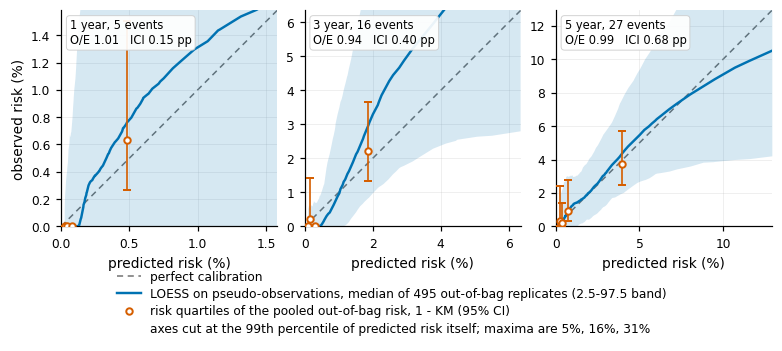

In [18]:
# ---- Figure A: out-of-bag calibration curves ---------------------------------
CURVE_C, GROUP_C = CONFIG["palette_calibration"]


def _calibration_panel(ax, kind, horizon, show_ylabel):
    d = SMOOTH[(kind, float(horizon))]
    # Both axes stop at the 99th percentile of predicted risk itself, on x and on y
    # alike, so the diagonal runs corner to corner. The predicted-risk lattice is
    # sparse up there, so the last native grid point can sit well below the
    # percentile (11.6% against 12.9% at five years); the curve and band are linearly
    # interpolated onto the percentile itself rather than stopping one lattice step
    # short of it, so the figure shows the same value the text quotes there. The one
    # other thing allowed to push the limit back out is a risk-group interval that
    # would otherwise be cut off - losing a confidence interval to a tidier axis is
    # not a trade worth making.
    lim = d["x_upper"]
    lim = max(lim, float(d["groups"]["obs_hi"].max()) * 1.02)
    pct = 100.0 * lim

    ax.plot([0, pct], [0, pct], color="0.45", lw=1.0, ls=(0, (4, 3)), zorder=1)

    m = d["grid"] <= lim
    grid_m, curve_m = d["grid"][m], d["curve"][m]
    lo_m, hi_m = d["band_lo"][m], d["band_hi"][m]
    if grid_m.size == 0 or grid_m[-1] < lim:
        grid_m = np.append(grid_m, lim)
        curve_m = np.append(curve_m, np.interp(lim, d["grid"], d["curve"]))
        lo_m = np.append(lo_m, np.interp(lim, d["grid"], d["band_lo"]))
        hi_m = np.append(hi_m, np.interp(lim, d["grid"], d["band_hi"]))
    ax.fill_between(100 * grid_m, 100 * lo_m, 100 * hi_m,
                    color=CURVE_C, alpha=0.16, lw=0, zorder=2)
    ax.plot(100 * grid_m, 100 * curve_m, color=CURVE_C, zorder=4)

    g = d["groups"]
    ax.errorbar(100 * g["pred_mean"], 100 * g["obs"],
                yerr=np.vstack([100 * (g["obs"] - g["obs_lo"]),
                                100 * (g["obs_hi"] - g["obs"])]),
                fmt="o", ms=4.2, mfc="white", mew=1.3, color=GROUP_C,
                elinewidth=1.1, capsize=2.4, zorder=5)

    row = CALIBRATION_TABLE.query("horizon == @horizon and validation == @kind").iloc[0]
    ax.text(0.04, 0.96,
            f"{horizon / DIV:.0f} year, {int(row['events'])} events\n"
            f"O/E {row['OE']:.2f}   ICI {100 * row['ICI']:.2f} pp",
            transform=ax.transAxes, va="top", ha="left",
            fontsize=CONFIG["font_size"] - 1.5, linespacing=1.4, zorder=6,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.8", lw=0.6, alpha=0.92))

    ax.set_xlim(0, pct)
    ax.set_ylim(0, pct)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("predicted risk (%)")
    if show_ylabel:
        ax.set_ylabel("observed risk (%)")
    return lim


fig, axes = plt.subplots(1, PLOT_HORIZONS.size,
                         figsize=(CONFIG["figure_width_in"], 3.0),
                         constrained_layout=True)
for _k, (_ax, _h) in enumerate(zip(np.atleast_1d(axes), PLOT_HORIZONS)):
    _calibration_panel(_ax, "out-of-bag", float(_h), show_ylabel=(_k == 0))

# The truncation applies to all three panels, so it is stated once rather than
# repeated inside each of them.
_maxima = ", ".join(f"{100 * SMOOTH[('out-of-bag', float(h))]['x_max']:.0f}%"
                    for h in PLOT_HORIZONS)
fig.legend(handles=[
    Line2D([], [], color="0.45", ls=(0, (4, 3)), lw=1.0, label="perfect calibration"),
    Line2D([], [], color=CURVE_C, lw=1.6,
           label=f"LOESS on pseudo-observations, median of {N_OK} out-of-bag "
                 f"replicates (2.5-97.5 band)"),
    Line2D([], [], color=GROUP_C, marker="o", ms=4.2, mfc="white", mew=1.3, ls="none",
           label="risk quartiles of the pooled out-of-bag risk, 1 - KM (95% CI)"),
    Line2D([], [], ls="none",
           label=f"axes cut at the {100 * CONFIG['plot_risk_upper_quantile']:.0f}th "
                 f"percentile of predicted risk itself; maxima are {_maxima}"),
], loc="lower center", bbox_to_anchor=(0.5, -0.19), ncol=1, frameon=False,
   handletextpad=0.7, labelspacing=0.35)

_save(fig, "figA_calibration_oob")
plt.show()

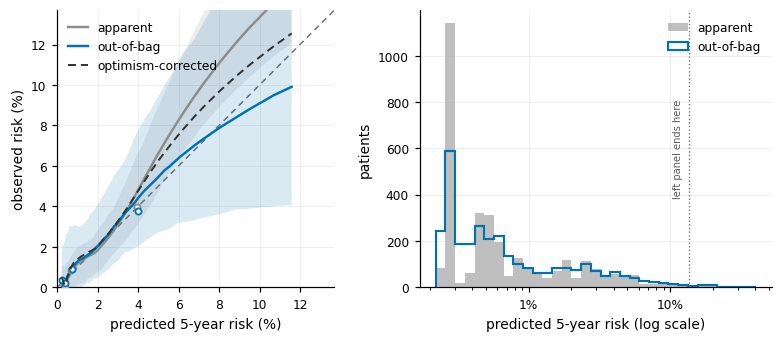

In [19]:
# ---- Figure B: apparent vs out-of-bag at the primary horizon ----------------
# Left: the curves on one pair of axes - the gap between apparent and out-of-bag IS the
# optimism, and the corrected curve is what removing it leaves. Right: the risk
# distribution on a log scale, because the two panels are the same question - the gap
# lives almost entirely in the sparse right tail, and the histogram says how sparse.
AP_C, OOB_C, COR_C = CONFIG["palette_validation"]

fig = plt.figure(figsize=(CONFIG["figure_width_in"], 3.0), constrained_layout=True)
gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.15])
ax0, ax1 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

_lims = []
for _kind in ("apparent", "out-of-bag"):
    _d = SMOOTH[(_kind, PRIMARY)]
    _lims.append(max(_d["x_upper"], _d["groups"]["obs_hi"].max()))
_lim = float(np.ceil(max(_lims) * 1.06 * 1000) / 1000) * 100

ax0.plot([0, _lim], [0, _lim], color="0.45", lw=1.0, ls=(0, (4, 3)), zorder=1)
for _kind, _c in (("apparent", AP_C), ("out-of-bag", OOB_C)):
    _d = SMOOTH[(_kind, PRIMARY)]
    _m = _d["grid"] * 100 <= _lim
    ax0.fill_between(100 * _d["grid"][_m], 100 * _d["band_lo"][_m], 100 * _d["band_hi"][_m],
                     color=_c, alpha=0.15, lw=0, zorder=2)
    ax0.plot(100 * _d["grid"][_m], 100 * _d["curve"][_m], color=_c, zorder=4, label=_kind)
    _g = _d["groups"]
    ax0.plot(100 * _g["pred_mean"], 100 * _g["obs"], "o", ms=4.0, mfc="white",
             mew=1.2, color=_c, ls="none", zorder=5)

if CONFIG["compute_optimism"]:
    # No band: the corrected curve's interval is the optimism's, which is already the
    # distance between the two curves either side of it.
    _d = SMOOTH[("optimism-corrected", PRIMARY)]
    _m = _d["grid"] * 100 <= _lim
    ax0.plot(100 * _d["grid"][_m], 100 * _d["curve"][_m], color=COR_C, lw=1.3,
             ls=(0, (4, 2.5)), zorder=6, label="optimism-corrected")

ax0.set_xlim(0, _lim)
ax0.set_ylim(0, _lim)
ax0.set_aspect("equal", adjustable="box")
ax0.set_xlabel(f"predicted {PRIMARY / DIV:.0f}-year risk (%)")
ax0.set_ylabel("observed risk (%)")
ax0.legend(loc="upper left", frameon=False, handlelength=1.6)

_bins = np.logspace(np.log10(max(RISK_APPARENT[:, HZ_IDX[-1]].min(), 1e-4)),
                    np.log10(RISK_APPARENT[:, HZ_IDX[-1]].max()), 34)
ax1.hist(RISK_APPARENT[:, HZ_IDX[-1]], bins=_bins, color=AP_C, alpha=0.55,
         label="apparent", lw=0)
ax1.hist(RISK_OOB[:, HZ_IDX[-1]], bins=_bins, histtype="step", color=OOB_C,
         lw=1.4, label="out-of-bag")
ax1.set_xscale("log")
ax1.set_xlabel(f"predicted {PRIMARY / DIV:.0f}-year risk (log scale)")
ax1.set_ylabel("patients")
ax1.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(
    lambda v, _: f"{100 * v:g}%"))
ax1.axvline(_lim / 100, color="0.45", lw=0.9, ls=":")
ax1.annotate("left panel ends here", xy=(_lim / 100, 0.32), xycoords=("data", "axes fraction"),
             xytext=(-4, 0), textcoords="offset points", rotation=90, ha="right", va="bottom",
             fontsize=CONFIG["font_size"] - 2.5, color="0.35")
ax1.legend(loc="upper right", frameon=False, handlelength=1.6)

_save(fig, "figB_apparent_vs_oob")
plt.show()

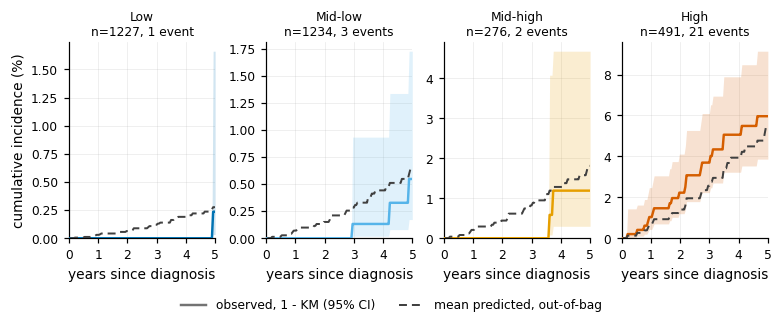

In [20]:
# ---- Figure C: predicted vs observed cumulative incidence, by deployed zone --
_yrs = EVAL_TIMES / DIV
fig, axes = plt.subplots(1, 4, figsize=(CONFIG["figure_width_in"], 2.55),
                         sharex=True, constrained_layout=True)

for _z, _ax in zip((1, 2, 3, 4), axes):
    _c = CONFIG["palette_zones"][_z - 1]
    _d = ZONE_CURVES[_z]
    _n_ev = int(np.count_nonzero(EVENT[ZONE == _z]))

    _ax.fill_between(_yrs, 100 * _d["observed_lo"], 100 * _d["observed_hi"],
                     color=_c, alpha=0.18, lw=0, zorder=2)
    _ax.plot(_yrs, 100 * _d["observed"], color=_c, zorder=4)
    _ax.plot(_yrs, 100 * _d["predicted_oob"], color="0.25", lw=1.3, ls=(0, (4, 2.5)), zorder=5)

    _ax.set_title(f"{CONFIG['zone_display_names'][_z - 1]}\n"
                  f"n={_d['n']}, {_n_ev} event{'' if _n_ev == 1 else 's'}",
                  fontsize=CONFIG["font_size"] - 1, pad=4)
    _ax.set_xlabel(f"{CONFIG['time_display_unit']} since diagnosis")
    _ax.set_xlim(0, PRIMARY / DIV)
    _ax.set_xticks([0, 1, 2, 3, 4, 5])

axes[0].set_ylabel("cumulative incidence (%)")
# The zones differ by an order of magnitude in risk; a shared y-axis would flatten
# the first three into the floor, so each panel keeps its own scale and the tick
# labels carry the comparison.
for _ax in axes:
    _ax.set_ylim(bottom=0)

fig.legend(handles=[
    Line2D([], [], color="0.45", lw=1.6, label="observed, 1 - KM (95% CI)"),
    Line2D([], [], color="0.25", lw=1.3, ls=(0, (4, 2.5)),
           label="mean predicted, out-of-bag"),
], loc="lower center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)

_save(fig, "figC_zone_calibration")
plt.show()

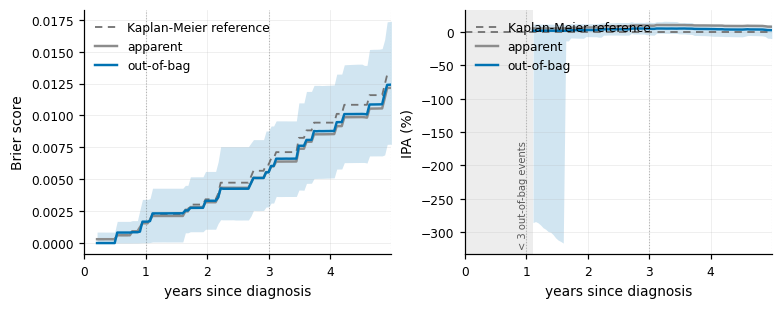

In [21]:
# ---- Figure D: Brier score and IPA against the Kaplan-Meier reference -------
# The apparent curves are scored against the cohort Kaplan-Meier; the out-of-bag band
# is scored against an in-bag Kaplan-Meier refitted in every replicate, which is the
# comparison that keeps model and null on the same footing.
_byrs = BS_TIMES / DIV
fig, (ax_b, ax_i) = plt.subplots(1, 2, figsize=(CONFIG["figure_width_in"], 2.7),
                                 constrained_layout=True)

ax_b.plot(_byrs, BS_REFERENCE, color="0.45", lw=1.2, ls=(0, (4, 3)),
          label="Kaplan-Meier reference")
ax_b.plot(_byrs, BS_APPARENT, color=AP_C, label="apparent")
ax_b.fill_between(_byrs, BS_OOB_LO, BS_OOB_HI, color=OOB_C, alpha=0.18, lw=0)
ax_b.plot(_byrs, BS_OOB, color=OOB_C, label="out-of-bag")
ax_b.set_xlabel(f"{CONFIG['time_display_unit']} since diagnosis")
ax_b.set_ylabel("Brier score")
ax_b.set_xlim(0, PRIMARY / DIV)
ax_b.legend(loc="upper left", frameon=False, handlelength=1.8)

ax_i.axhline(0.0, color="0.45", lw=1.2, ls=(0, (4, 3)),
             label="Kaplan-Meier reference")
ax_i.plot(_byrs, 100 * IPA_APPARENT, color=AP_C, label="apparent")
ax_i.fill_between(_byrs, 100 * IPA_OOB_LO, 100 * IPA_OOB_HI, color=OOB_C, alpha=0.18, lw=0)
ax_i.plot(_byrs, 100 * IPA_OOB, color=OOB_C, label="out-of-bag")
ax_i.set_xlabel(f"{CONFIG['time_display_unit']} since diagnosis")
ax_i.set_ylabel("IPA (%)")
ax_i.set_xlim(0, PRIMARY / DIV)
ax_i.legend(loc="upper left", frameon=False, handlelength=1.8)
# Both IPA curves start where the held-out patients have events to score; before that
# the ratio is 0/0 (see the Brier cell).
ax_i.axvspan(0, IPA_START / DIV, color="0.85", alpha=0.45, lw=0, zorder=0)
ax_i.annotate(f"< {CONFIG['ipa_min_oob_events']} out-of-bag events",
              xy=(IPA_START / DIV, 0.02), xycoords=("data", "axes fraction"),
              xytext=(-3, 0), textcoords="offset points", rotation=90,
              ha="right", va="bottom", fontsize=CONFIG["font_size"] - 2.5, color="0.35")

for _ax in (ax_b, ax_i):
    for _h in PLOT_HORIZONS:
        _ax.axvline(_h / DIV, color="0.7", lw=0.7, ls=":", zorder=0)

_save(fig, "figD_brier_ipa")
plt.show()

In [ ]:
# ---- Figure E: the thesis figure - 5-year out-of-bag calibration -------------
# One panel, one horizon, out of bag only. Figures A-D above are the supporting
# material; this is the single plot the calibration section of the thesis carries.
# Standalone: loads the cache written at the end of the "calibration curves and
# their bands" cell (calibration/_smooth_cache.pkl), so only this cell needs to
# run after a kernel restart - no need to rerun the bootstrap for a figure tweak.
import os
import pickle

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

with open(os.path.join("calibration", "_smooth_cache.pkl"), "rb") as _fh:
    _cache = pickle.load(_fh)
CONFIG = _cache["CONFIG"]
DIV, PRIMARY = _cache["DIV"], _cache["PRIMARY"]
SMOOTH, CALIBRATION_TABLE = _cache["SMOOTH"], _cache["CALIBRATION_TABLE"]
CURVE_C, GROUP_C = CONFIG["palette_calibration"]

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "font.size": CONFIG["font_size"],
    "axes.titlesize": CONFIG["font_size"],
    "axes.labelsize": CONFIG["font_size"],
    "xtick.labelsize": CONFIG["font_size"] - 1,
    "ytick.labelsize": CONFIG["font_size"] - 1,
    "legend.fontsize": CONFIG["font_size"] - 1,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 1.6,
})


def _calibration_panel(ax, kind, horizon, show_ylabel):
    d = SMOOTH[(kind, float(horizon))]
    lim = d["x_upper"]
    lim = max(lim, float(d["groups"]["obs_hi"].max()) * 1.02)
    pct = 100.0 * lim

    ax.plot([0, pct], [0, pct], color="0.45", lw=1.0, ls=(0, (4, 3)), zorder=1)

    m = d["grid"] <= lim
    grid_m, curve_m = d["grid"][m], d["curve"][m]
    lo_m, hi_m = d["band_lo"][m], d["band_hi"][m]
    if grid_m.size == 0 or grid_m[-1] < lim:
        grid_m = np.append(grid_m, lim)
        curve_m = np.append(curve_m, np.interp(lim, d["grid"], d["curve"]))
        lo_m = np.append(lo_m, np.interp(lim, d["grid"], d["band_lo"]))
        hi_m = np.append(hi_m, np.interp(lim, d["grid"], d["band_hi"]))
    ax.fill_between(100 * grid_m, 100 * lo_m, 100 * hi_m,
                    color=CURVE_C, alpha=0.16, lw=0, zorder=2)
    ax.plot(100 * grid_m, 100 * curve_m, color=CURVE_C, zorder=4)

    g = d["groups"]
    ax.errorbar(100 * g["pred_mean"], 100 * g["obs"],
                yerr=np.vstack([100 * (g["obs"] - g["obs_lo"]),
                                100 * (g["obs_hi"] - g["obs"])]),
                fmt="o", ms=4.2, mfc="white", mew=1.3, color=GROUP_C,
                elinewidth=1.1, capsize=2.4, zorder=5)

    row = CALIBRATION_TABLE.query("horizon == @horizon and validation == @kind").iloc[0]
    ax.text(0.04, 0.96,
            f"{horizon / DIV:.0f} year, {int(row['events'])} events\n"
            f"O/E {row['OE']:.2f}   ICI {100 * row['ICI']:.2f} pp",
            transform=ax.transAxes, va="top", ha="left",
            fontsize=CONFIG["font_size"] - 1.5, linespacing=1.4, zorder=6,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.8", lw=0.6, alpha=0.92))

    ax.set_xlim(0, pct)
    ax.set_ylim(0, pct)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("predicted risk (%)")
    if show_ylabel:
        ax.set_ylabel("observed risk (%)")
    return lim


def _save(fig, stem):
    if not CONFIG["save_figures"]:
        return
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join("calibration", f"{stem}.{ext}"))


fig, ax = plt.subplots(figsize=(5.4, 3.5), constrained_layout=True)
LIM_E = _calibration_panel(ax, "out-of-bag", PRIMARY, show_ylabel=True)

fig.legend(handles=[
    Line2D([], [], color="0.45", ls=(0, (4, 3)), lw=1.0, label="perfect calibration"),
    Line2D([], [], color=CURVE_C, lw=1.6,
           label=f"LOESS on pseudo-observations, median of the out-of-bag "
                 f"replicates (2.5-97.5 band)"),
    Line2D([], [], color=GROUP_C, marker="o", ms=4.2, mfc="white", mew=1.3, ls="none",
           label="risk quartiles of the pooled out-of-bag risk, 1 - KM (95% CI)"),
], loc="center left", bbox_to_anchor=(1.0, 0.5), ncol=1, frameon=False,
   handletextpad=0.7, labelspacing=0.8)

_save(fig, "figE_calibration_5y")
plt.show()

# For the caption and the discussion: where the axes stop, and how wide the band is at
# that edge - the honest measure of what 27 events, ~10 of them out of bag per
# replicate, can say.
_d = SMOOTH[("out-of-bag", PRIMARY)]
print(f"figE axes cut at {100 * LIM_E:.2f}% - the "
      f"{100 * CONFIG['plot_risk_upper_quantile']:.0f}th percentile of predicted risk "
      f"itself; maximum predicted {100 * _d['x_max']:.1f}%")
for _x in sorted({0.01, 0.03, LIM_E}):
    _lo = float(np.interp(_x, _d["grid"], _d["band_lo"]))
    _hi = float(np.interp(_x, _d["grid"], _d["band_hi"]))
    print(f"  at {100 * _x:5.2f}% predicted : curve "
          f"{100 * float(np.interp(_x, _d['grid'], _d['curve'])):5.2f}%, "
          f"band {100 * _lo:5.2f}-{100 * _hi:5.2f}%")

## 8. Tables

Seven CSVs, one of them also written as LaTeX. `table1_calibration_thesis.tex` is the one
meant for the thesis body; the rest are supporting material.

- **table1_calibration** - per horizon, apparent / out-of-bag / optimism-corrected:
  observed, predicted, O/E, slope, ICI, E90, each with its interval.
- **table2_zone_calibration** - predicted against observed inside the four deployed zones.
- **table3_brier_ipa** - Brier score and IPA over follow-up.
- **table5_ibs** - the integrated Brier score over 0-5 years, the summary of table 3.
- **table4_bootstrap_per_replicate** - every statistic for every replicate and every
  evaluation, so any aggregate above can be traced back to the replicates it came from.
- **table6_replicate_log** - one row per replicate: seed, in-bag/out-of-bag sizes,
  out-of-bag events, non-zero coefficients, runtime.
- **table7_replicate_failures** - the replicates whose fit was rejected, with the reason.
  Written only when there are any.

In [23]:
# ---- Export the tables ------------------------------------------------------
_save_table(CALIBRATION_TABLE, "table1_calibration")
_save_table(ZONE_TABLE, "table2_zone_calibration")
_save_table(BRIER_TABLE, "table3_brier_ipa")
_save_table(BOOT_PER_REPLICATE, "table4_bootstrap_per_replicate")
_save_table(IBS_TABLE, "table5_ibs")
_save_table(REPLICATE_LOG, "table6_replicate_log")
if len(FAILURES):
    _save_table(FAILURES, "table7_replicate_failures")

# The thesis-body version of table 1. Every cell is pre-formatted as a string:
# to_latex's float_format would otherwise re-pad the rounded values back out to a
# common precision, and the '%' signs are left bare for escape=True to handle.
_tex1 = pd.DataFrame({
    "Horizon (y)": (CALIBRATION_TABLE["horizon"] / DIV).round(0).astype(int),
    "Validation": CALIBRATION_TABLE["validation"].astype(str),
    "Events": CALIBRATION_TABLE["events"],
    "Observed % (95% CI)": [
        f"{100 * o:.2f} ({100 * l:.2f}--{100 * h:.2f})"
        for o, l, h in zip(CALIBRATION_TABLE.observed, CALIBRATION_TABLE.observed_lo,
                           CALIBRATION_TABLE.observed_hi)],
    "Predicted %": [f"{100 * v:.2f}" for v in CALIBRATION_TABLE["predicted"]],
    "O/E": [f"{v:.2f} ({l:.2f}--{h:.2f})" for v, l, h in
            zip(CALIBRATION_TABLE.OE, CALIBRATION_TABLE.OE_lo, CALIBRATION_TABLE.OE_hi)],
    "Slope": [f"{v:.2f} ({l:.2f}--{h:.2f})" for v, l, h in
              zip(CALIBRATION_TABLE.slope, CALIBRATION_TABLE.slope_lo,
                  CALIBRATION_TABLE.slope_hi)],
    "ICI (pp)": [f"{100 * v:.3f}" for v in CALIBRATION_TABLE["ICI"]],
    "E90 (pp)": [f"{100 * v:.3f}" for v in CALIBRATION_TABLE["E90"]],
})
_save_table(
    _tex1, "table1_calibration_thesis",
    tex_caption=(
        "Calibration of the deployed L1-Coxnet model. Observed risk is $1-\\hat S(t)$ "
        "from the cohort Kaplan-Meier estimator. Apparent rows come from the full-cohort "
        f"fit. The internal validation is the event-stratified bootstrap this repository "
        f"uses to assess metrics: {CALIBRATION_TABLE['n_replicates'].iloc[0]} replicates, "
        "each refitting the scaler and the model on its in-bag rows. Out-of-bag rows are "
        "the median over replicates of the statistic computed on that replicate's "
        "held-out patients; optimism-corrected rows are the apparent value minus the "
        "mean of (in-bag $-$ original-cohort), the Efron-Harrell correction. Intervals "
        "are 2.5--97.5 percentiles over replicates (for the apparent rows, of the in-bag "
        "replicates). ICI and E90 are absolute risk differences in percentage points; "
        "being means of absolute deviations they grow with resampling noise, so their "
        "apparent interval can sit above the apparent value and the correction is not "
        "range-preserving - quote the out-of-bag row for those two columns."),
    tex_label="tab:calibration",
)
print("wrote", len([w for w in WRITTEN if w.endswith((".csv", ".tex"))]), "table files")

wrote 11 table files


## 9. Reproducibility

The run metadata and a regression test, in the shape `threshold_2.0_copy.ipynb` uses:
`run_metadata.json` records the config, the library versions and the headline numbers, so
a later run can be diffed against this one rather than eyeballed against it.

In [24]:
# ---- Regression test and run metadata ---------------------------------------
_p = CALIBRATION_TABLE.query("horizon == @PRIMARY and validation == 'apparent'").iloc[0]
_o = CALIBRATION_TABLE.query("horizon == @PRIMARY and validation == 'out-of-bag'").iloc[0]
_c = (CALIBRATION_TABLE.query("horizon == @PRIMARY and validation == 'optimism-corrected'").iloc[0]
      if CONFIG["compute_optimism"] else None)

# Things that must hold if the notebook did what it says it did.
assert np.isclose(C_APPARENT, CONFIG["expected_apparent_c_index"], atol=1e-10)
assert [int((ZONE == z).sum()) for z in (1, 2, 3, 4)] == CONFIG["zone_expected_sizes"]
assert int(_p["events"]) == int(EVENT.sum()) == BUNDLE_META["n_events"]
# The Breslow baseline is fitted on the scoring set, so apparent O/E is pinned near 1.
assert abs(_p["OE"] - 1.0) < 0.05, f"apparent O/E drifted to {_p['OE']:.3f}"
# Out-of-bag risks must be genuinely out of bag: never identical to the apparent ones.
assert not np.allclose(RISK_OOB, RISK_APPARENT)
# Every patient must have been held out at least once, and no replicate may have kept
# an out-of-bag row in its training sample.
assert (OOB_COUNT > 0).all()
print("regression checks passed")

RUN_METADATA = {
    "generated": datetime.now().isoformat(timespec="seconds"),
    "notebook": "calibration.ipynb",
    "model_source": os.path.relpath(CONFIG["bundle_metadata"], "."),
    "library_versions": LIB_VERSIONS,
    "config": CONFIG,
    "cohort": {
        "n_patients": N_PATIENTS,
        "n_events": int(EVENT.sum()),
        "events_by_horizon": {str(int(h)): int((EVENT & (TIME <= h)).sum()) for h in HORIZONS},
        "apparent_c_index": C_APPARENT,
        "n_nonzero_coefficients": N_NONZERO,
    },
    "bootstrap": {
        "n_requested": int(B),
        "n_successful": int(N_OK),
        "n_failed": int(len(FAILURES)),
        "failure_modes": (FAILURES["error"].value_counts().to_dict()
                          if len(FAILURES) else {}),
        "kinds": list(KINDS),
        "mean_oob_rows": float(REPLICATE_LOG["n_oob"].mean()),
        "mean_oob_events": float(REPLICATE_LOG["n_oob_events"].mean()),
        "mean_seconds_per_replicate": float(REPLICATE_LOG["seconds"].mean()),
    },
    "discrimination": DISCRIMINATION,
    "integrated_brier_score": IBS,
    "headline": {
        f"{int(PRIMARY)}d": {
            kind: {k: float(row[k]) for k in ("observed", "predicted", "OE", "slope",
                                              "ICI", "E50", "E90", "Emax")}
            for kind, row in (("apparent", _p), ("out_of_bag", _o),
                              ("optimism_corrected", _c))
            if row is not None
        }
    },
}
_meta_path = os.path.join(OUTPUT_DIR, "run_metadata.json")
with open(_meta_path, "w", encoding="utf-8") as _fh:
    json.dump(RUN_METADATA, _fh, indent=2, default=str)
WRITTEN.append(os.path.relpath(_meta_path, os.getcwd()))
print("wrote", os.path.relpath(_meta_path, os.getcwd()))

regression checks passed
wrote calibration\run_metadata.json


In [25]:
# ---- What was written, and what it says -------------------------------------
print("files written to", os.path.relpath(OUTPUT_DIR, os.getcwd()))
for _w in sorted(set(WRITTEN)):
    print("  ", _w)

print(f"\nHeadline, {PRIMARY / DIV:.0f}-year horizon, {int(EVENT.sum())} events, "
      f"{N_OK} bootstrap replicates:")
print(f"  observed                 {100 * _p['observed']:.2f}% "
      f"({100 * _p['observed_lo']:.2f}-{100 * _p['observed_hi']:.2f}%)")
for _label, _row in (("apparent", _p), ("out-of-bag", _o), ("optimism-corrected", _c)):
    if _row is None:
        continue
    print(f"  predicted, {_label:<18s} {100 * _row['predicted']:.2f}%   "
          f"O/E {_row['OE']:.3f} [{_row['OE_lo']:.3f}, {_row['OE_hi']:.3f}]   "
          f"slope {_row['slope']:.2f} [{_row['slope_lo']:.2f}, {_row['slope_hi']:.2f}]   "
          f"ICI {100 * _row['ICI']:.3f} pp")
print(f"  C-index    apparent {DISCRIMINATION['c_apparent']:.4f}   "
      f"out-of-bag {DISCRIMINATION['c_oob_median']:.4f} "
      f"[{DISCRIMINATION['c_oob_lo']:.4f}, {DISCRIMINATION['c_oob_hi']:.4f}]"
      + (f"   optimism-corrected {DISCRIMINATION['c_final']:.4f} "
         f"[{DISCRIMINATION['c_final_lo']:.4f}, {DISCRIMINATION['c_final_hi']:.4f}]"
         if CONFIG["compute_optimism"] else ""))
print(f"  C-index    apparent (IPCW) {DISCRIMINATION['c_apparent_ipcw']:.4f}")

files written to calibration
   calibration\figA_calibration_oob.pdf
   calibration\figA_calibration_oob.png
   calibration\figB_apparent_vs_oob.pdf
   calibration\figB_apparent_vs_oob.png
   calibration\figC_zone_calibration.pdf
   calibration\figC_zone_calibration.png
   calibration\figD_brier_ipa.pdf
   calibration\figD_brier_ipa.png
   calibration\figE_calibration_5y.pdf
   calibration\figE_calibration_5y.png
   calibration\figF_risk_distribution.pdf
   calibration\figF_risk_distribution.png
   calibration\run_metadata.json
   calibration\table1_calibration.csv
   calibration\table1_calibration_thesis.csv
   calibration\table1_calibration_thesis.tex
   calibration\table2_zone_calibration.csv
   calibration\table3_brier_ipa.csv
   calibration\table4_bootstrap_per_replicate.csv
   calibration\table5_ibs.csv
   calibration\table6_replicate_log.csv
   calibration\table7_replicate_failures.csv
   calibration\table8_risk_distribution_summary.csv
   calibration\table8_risk_distribution_su